# 🌐 Global Arms Transfer Network Analysis (2000–2023)

**Name / NIM:** Jason Wijaya / 191900531  

---

## List of Contents
1. [Setup & Data Loading](#1)
2. [Exploratory Data Analysis (EDA)](#2)
3. [Build Network Graph](#3)
4. [Degree Distribution](#4)
5. [Clustering Coefficients](#5)
6. [Average Path Length & Diameter](#6)
7. [Centrality Measures](#7)
8. [Network Visualisations (4 Layouts)](#8)
9. [Community Detection & Geopolitical Blocs](#9)
10. [Summary](#10)

## 1. Setup & Data Loading

Import all required libraries and load the raw dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
import powerlaw
import warnings, random
from scipy import stats
warnings.filterwarnings('ignore')

sns.set_style('darkgrid')   
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
})
print('Setup complete.')

Setup complete.


In [2]:
df_raw = pd.read_csv('datasets/global_arms_transfer_2000_2023.csv')
print(f'Shape: {df_raw.shape}')
df_raw.sample(10)

Shape: (10520, 15)


,id,trade_id,target,source,order_date,orderYrEst,quantity,delivery_date,designation,description,category,source_lat,source_lng,target_lat,target_lng
10042,311531,66575,Ukraine,Norway,2023-01-01 00:00:00+00:00,False,3.0,2023-01-01 00:00:00+00:00,ARTHUR,artillery locating radar,Sensors,59.842233,10.681371,49.215255,31.197760
3386,236051,51100,Mozambique,Brazil,2014-01-01 00:00:00+00:00,False,3.0,2014-01-01 00:00:00+00:00,EMB-312,trainer aircraft,Aircraft,-11.216050,-52.990579,-17.371829,35.436962
3603,233508,51539,UAE,United States,2011-01-01 00:00:00+00:00,False,12.0,2015-01-01 00:00:00+00:00,CH-47F,transport helicopter,Aircraft,38.893651,-77.170630,23.875788,54.210894
3800,263196,52069,Turkmenistan,Russia,2009-01-01 00:00:00+00:00,False,2.0,2009-01-01 00:00:00+00:00,Project-12200,patrol craft,Ships,64.774657,98.105107,39.146089,59.239318
6050,239116,58281,Oman,United States,2008-01-01 00:00:00+00:00,True,100.0,2010-01-01 00:00:00+00:00,Javelin ATM,anti-tank missile,Missiles,38.893651,-77.170630,20.654420,56.113623
4891,265081,55190,Estonia,Belgium,2010-01-01 00:00:00+00:00,True,25.0,2010-01-01 00:00:00+00:00,Mistral SAM,portable SAM,Missiles,50.658121,4.577773,58.655694,25.821991
1682,301838,35647,Nigeria,Italy,2002-01-01 00:00:00+00:00,True,18.0,2003-01-01 00:00:00+00:00,Model-56 105mm,towed gun,Artillery,42.920661,12.077566,9.571644,7.999782
3826,263208,52128,Burkina Faso,Romania,2009-01-01 00:00:00+00:00,False,5.0,2009-01-01 00:00:00+00:00,APR-40 122mm,self-propelled MRL,Artillery,45.891928,24.937764,12.319989,-1.773250
4584,264522,54358,Australia,United States,2011-01-01 00:00:00+00:00,False,2.0,2012-01-01 00:00:00+00:00,CH-47D Chinook,transport helicopter,Aircraft,38.893651,-77.170630,-26.234939,134.617710
7486,314612,61417,Netherlands,United States,2019-01-01 00:00:00+00:00,False,42.0,2023-01-01 00:00:00+00:00,AIM-120C AMRAAM,BVRAAM,Missiles,38.893651,-77.170630,52.312367,5.516262


In [3]:
print("Column Dtypes:")
print(df_raw.dtypes)
print("\nMissing values:")
print(df_raw.isnull().sum())

Column Dtypes:
id                 int64
trade_id           int64
target               str
source               str
order_date           str
orderYrEst        object
quantity         float64
delivery_date        str
designation          str
description          str
category             str
source_lat       float64
source_lng       float64
target_lat       float64
target_lng       float64
dtype: object

Missing values:
id                  0
trade_id            0
target              0
source              0
order_date          0
orderYrEst          4
quantity          228
delivery_date    1679
designation         0
description         0
category            0
source_lat        160
source_lng        160
target_lat        382
target_lng        382
dtype: int64


### 1.1 Data Cleaning

Steps:
1. **Remove non-state actors** (insurgent groups, alliances like `NATO**`) — non-states that can be mapped as meaningful nodes.
2. **Parse the year** from the `order_date` column using `pd.to_datetime` to create the `order_year` column.
3. **Impute missing quantities** with the median per weapon category, since the quantity distribution differs across categories (median aircraft ≠ median missile). Fallback to the global median if the category is also empty.

In [4]:
df = df_raw.copy()

# Remove non-state actors
pattern = r'\*|\bvarious\b|\bunknown\b'
df = df[
    ~df['source'].str.contains(pattern, case=False, na=False) &
    ~df['target'].str.contains(pattern, case=False, na=False)
].copy()
df = df[df['source'].notna() & df['target'].notna()]

df['order_year'] = pd.to_datetime(df['order_date']).dt.year

print(f"Clean shape: {df.shape}")
df.describe(include='all').T

Clean shape: (10230, 16)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,10230.0,NaN,NaN,NaN,273061.817498,30369.496749,229360.0,247936.25,263520.5,307244.5,317564.0
trade_id,10230.0,NaN,NaN,NaN,52404.018964,12104.014677,551.0,39720.25,56112.0,62166.75,67546.0
target,10230,184,Ukraine,353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,10230,96,United States,2995,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,10230,24,2022-01-01 00:00:00+00:00,639,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orderYrEst,10226,2,False,6263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,10018.0,NaN,NaN,NaN,109.882511,649.508095,0.0,3.0,10.0,46.0,25000.0
delivery_date,8582,24,2016-01-01 00:00:00+00:00,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
designation,10230,2287,Mi-17,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,10230,191,APC,813,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Impute missing quantity with median per category
df['quantity'] = df.groupby('category')['quantity'].transform(
    lambda x: x.fillna(x.median())
)
# fallback: global median
df['quantity'] = df['quantity'].fillna(df['quantity'].median())

print(f"Clean shape: {df.shape}")
print(f"Remaining NaN in quantity: {df['quantity'].isna().sum()}")
df.head(5)

Clean shape: (10230, 16)
Remaining NaN in quantity: 0


,id,trade_id,target,source,order_date,orderYrEst,quantity,delivery_date,designation,description,category,source_lat,source_lng,target_lat,target_lng,order_year
0,230885,551,Kyrgyzstan,Russia,2005-01-01 00:00:00+00:00,True,1.0,2005-01-01 00:00:00+00:00,Mi-17,transport helicopter,Aircraft,64.774657,98.105107,41.528863,74.636524,2005
2,272485,2511,Paraguay,Spain,2003-01-01 00:00:00+00:00,False,1.0,2004-01-01 00:00:00+00:00,C-212,transport aircraft,Aircraft,40.434162,-3.614563,-23.297918,-58.365255,2003
3,273685,3509,Greece,United States,2003-01-01 00:00:00+00:00,False,4.0,2007-01-01 00:00:00+00:00,APG-78 Longbow,combat heli radar,Sensors,38.893651,-77.170630,39.124398,22.720532,2003
5,309510,4639,China,Germany,2000-01-01 00:00:00+00:00,True,48.0,2006-01-01 00:00:00+00:00,ship engine 1001-2500,ship engine,Engines,51.247366,10.298068,37.594298,104.209271,2000
6,254003,4842,Indonesia,France,2004-01-01 00:00:00+00:00,True,30.0,2010-01-01 00:00:00+00:00,Exocet-40,anti-ship missile,Missiles,44.349371,-1.328556,-2.234137,117.431827,2004


## 2. Exploratory Data Analysis (EDA)

Before building a network, we need to understand the distribution of the raw data:
- How many transfers occur each year?
- Which countries export/import the most?
- Which weapon categories are transferred most frequently?
- What is the quantity distribution?

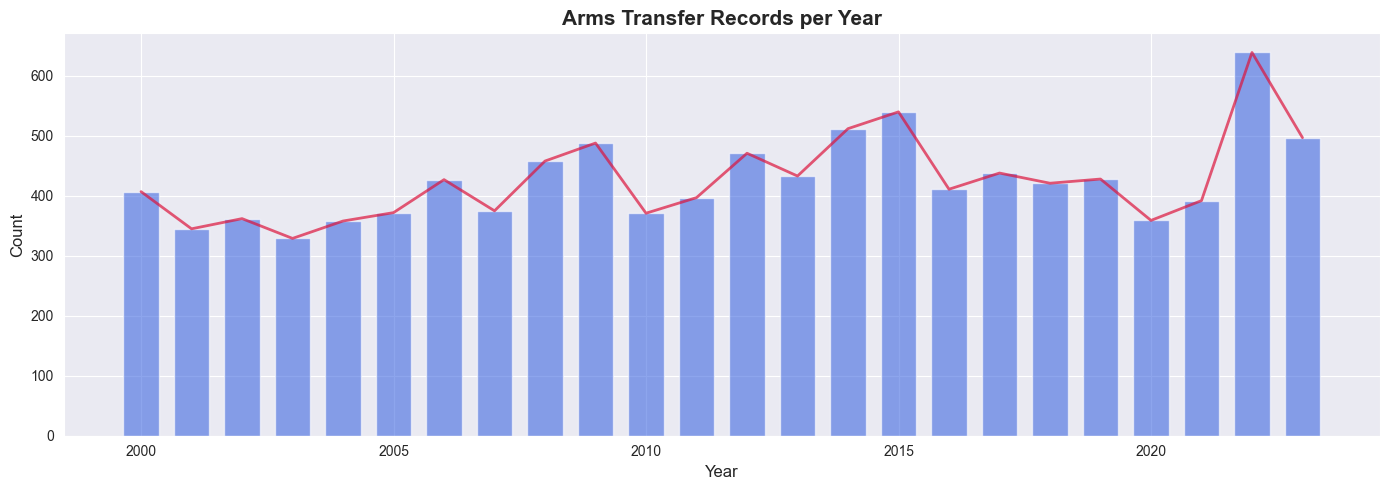

In [6]:
# 2a. Transfer per year
yearly = df.groupby('order_year').size()
fig, ax = plt.subplots(figsize=(14, 5))
years = yearly.index.dropna()
ax.bar(years, yearly[years], color='royalblue', alpha=0.6, width=0.7)
ax.plot(years, yearly[years], color='crimson', linewidth=2, alpha=0.7)
ax.set(title='Arms Transfer Records per Year', xlabel='Year', ylabel='Count')
plt.tight_layout()
plt.show()

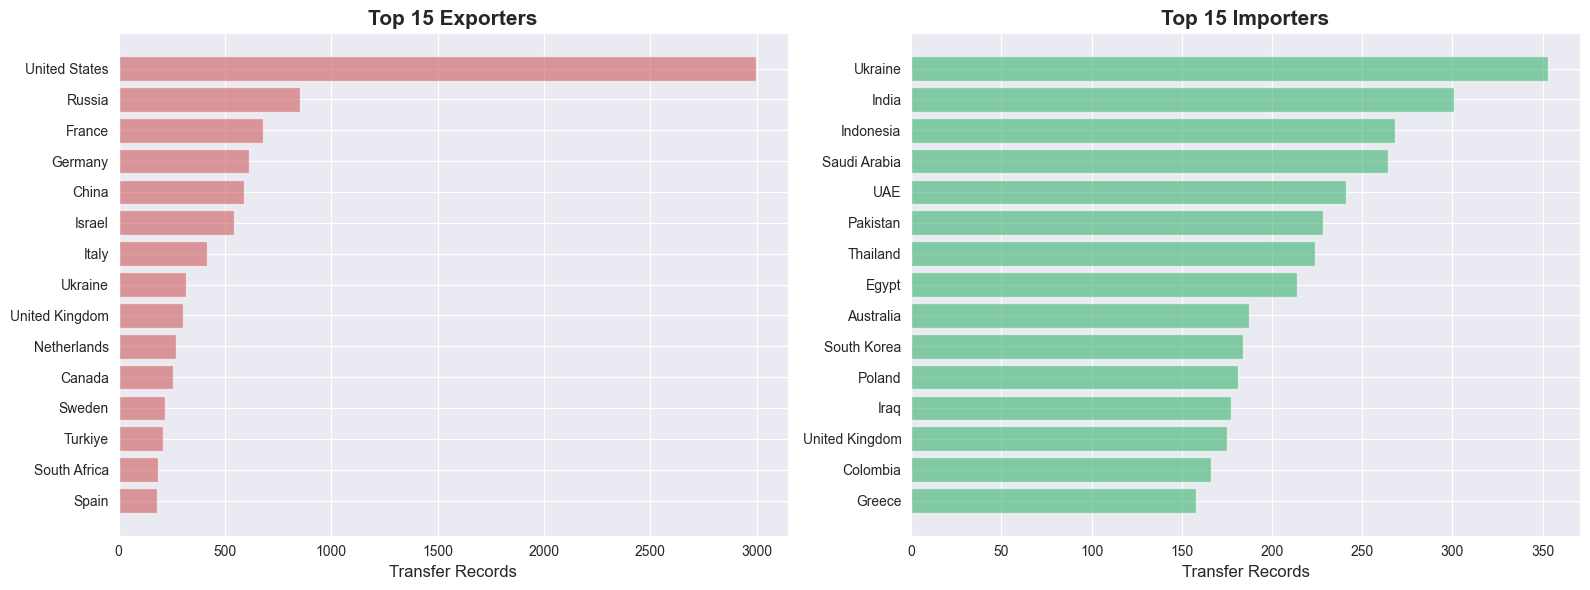

In [7]:
# 2b. Top exporters & importers
top_src = df['source'].value_counts().head(15)
top_tgt = df['target'].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title, col in zip(axes,
    [top_src, top_tgt], ['Top 15 Exporters', 'Top 15 Importers'], ['indianred', 'mediumseagreen']):
    ax.barh(data.index[::-1], data.values[::-1], color=col, alpha=0.6)
    ax.set(title=title, xlabel='Transfer Records')
plt.tight_layout()
plt.show()

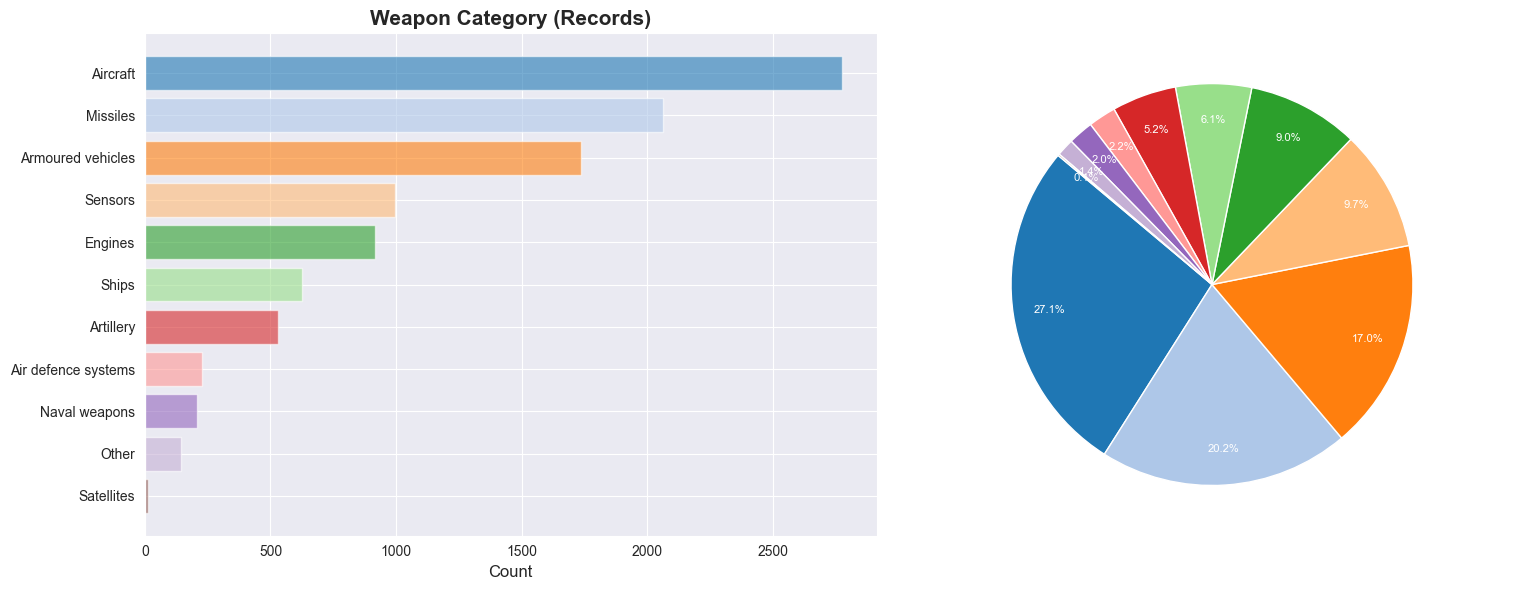

In [8]:
# 2c. Category breakdown
cat = df['category'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = plt.cm.tab20.colors[:len(cat)]

axes[0].barh(cat.index[::-1], cat.values[::-1], color=colors[::-1], alpha=0.6)
axes[0].set(title='Weapon Category (Records)', xlabel='Count')

axes[1].pie(cat.values, labels=cat.index, autopct='%1.1f%%',
            colors=colors, startangle=140,
            textprops={'color': 'white', 'fontsize': 8}, pctdistance=0.82)
plt.tight_layout()
plt.show()

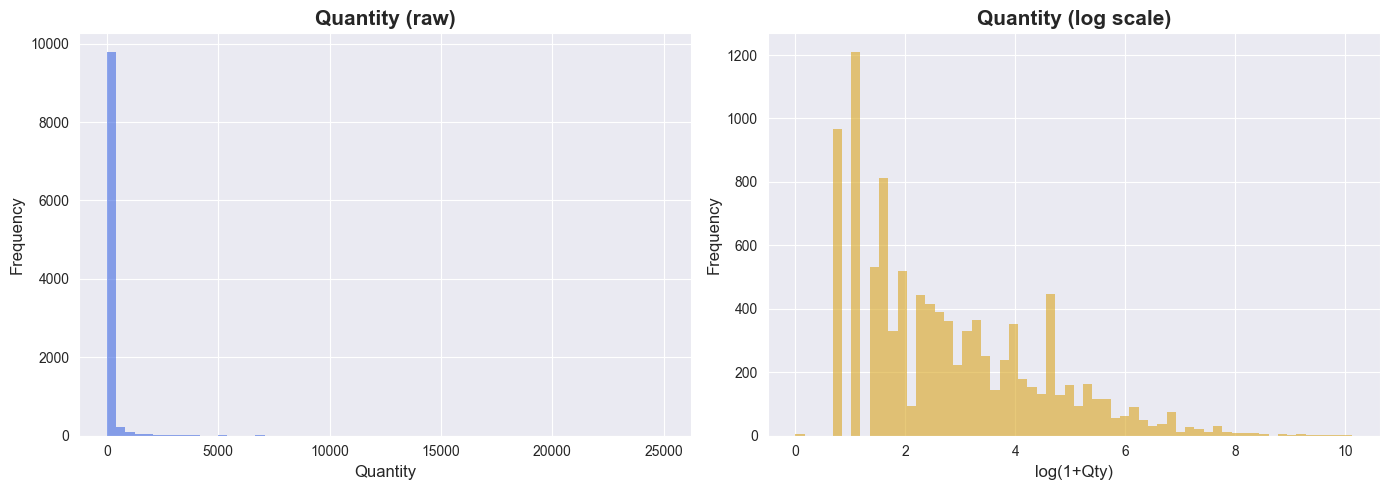

Min=0  Max=25000  Mean=109  Median=10


In [9]:
# 2d. Quantity distribution
qty = df['quantity'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(qty, bins=60, color='royalblue', edgecolor='none', alpha=0.6)
axes[0].set(title='Quantity (raw)',  xlabel='Quantity', ylabel='Frequency')
axes[1].hist(np.log1p(qty), bins=60, color='goldenrod', edgecolor='none', alpha=0.6)
axes[1].set(title='Quantity (log scale)', xlabel='log(1+Qty)', ylabel='Frequency')
plt.tight_layout()
plt.show()
print(f"Min={qty.min():.0f}  Max={qty.max():.0f}  Mean={qty.mean():.0f}  Median={qty.median():.0f}")

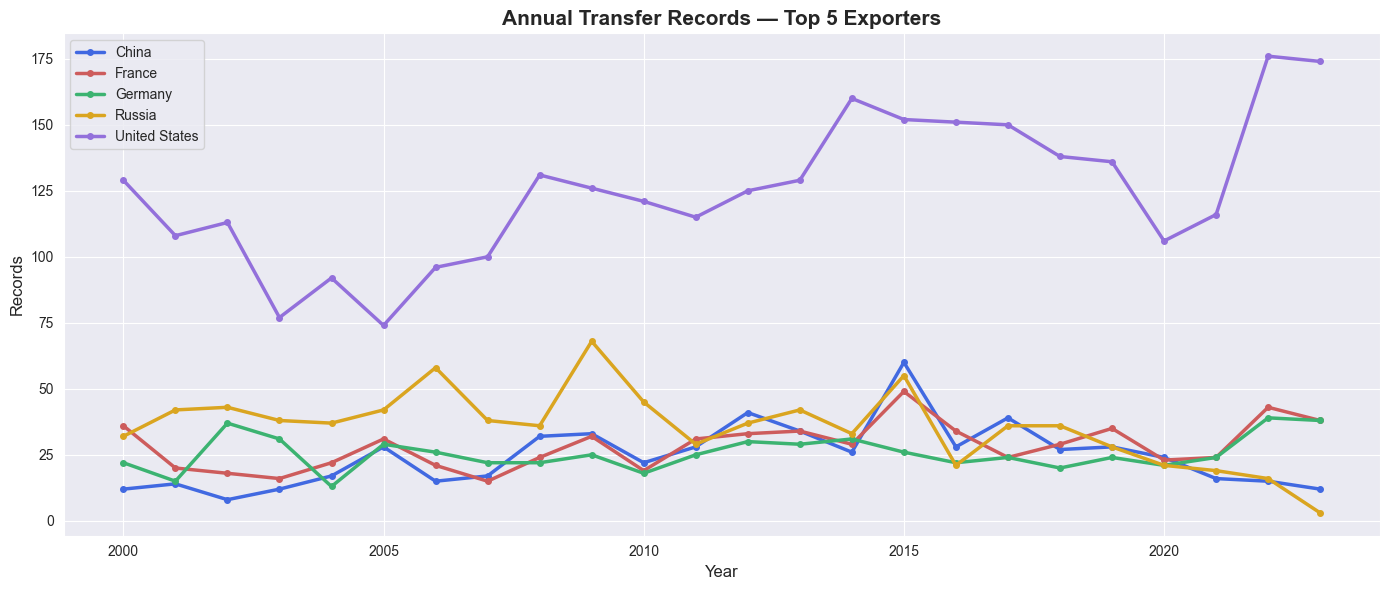

In [10]:
# 2e. Trade flow over time — top 5 exporters
top5_src = df['source'].value_counts().head(5).index
flow = (df[df['source'].isin(top5_src)]
        .groupby(['order_year','source']).size().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(14, 6))
for col, lc in zip(flow.columns, ['royalblue','indianred','mediumseagreen',
                                  'goldenrod','mediumpurple']):
    ax.plot(flow.index, flow[col], label=col, color=lc, lw=2.5, marker='o', markersize=4)
ax.set(title='Annual Transfer Records — Top 5 Exporters', xlabel='Year', ylabel='Records')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Build Network Graphs

Why use `SUM(quantity)` instead of `COUNT(transactions)`?

We define edge weights using total **transfered quantity** (`SUM(quantity)`) rather than transcation count:

| Weight | Interpretation | Limitation |
|--------|-------|---------|
| `COUNT(rows)` | Number of deals | Treats all deals equally (e.g., 1 rifle = 1 tank deal) |
| **`SUM(quantity)`** ✅ | Total units transferred | Captures true scale of military dependence

<br>

> ✅ Conclusion
> Using `SUM(quantity)` better reflect real-world influence and dependency in arms trade networks.

In [11]:
# Aggregation: source → target, weight = total quantity
edge_qty = (df.groupby(['source', 'target'])['quantity']
             .sum()
             .reset_index(name='weight_qty')
             .query('source != target'))

# normalized quantity
df['qty_norm'] = np.log1p(df['quantity'])

edge_norm = (df.groupby(['source', 'target'])['qty_norm']
             .sum()
             .reset_index(name='weight_qty_norm')
             .query('source != target'))

edge_df = (edge_qty
           .merge(edge_norm, on=['source', 'target']))

print("Weight statistics:")
print(edge_df[['weight_qty', 'weight_qty_norm']].describe().round(2))

Weight statistics:
       weight_qty  weight_qty_norm
count     1914.00          1914.00
mean       582.04            14.78
std       3681.05            37.03
min          1.00             0.69
25%          5.00             1.95
50%         24.00             4.71
75%        131.75            11.96
max      78339.00           498.86


In [12]:
G_qty = nx.DiGraph() # weighted (qty)
G_qnorm = nx.DiGraph() # weighted (normalized)
G_uw = nx.DiGraph() # unweighted

G_qty.add_weighted_edges_from(
    edge_df[['source','target','weight_qty']].itertuples(index=False, name=None)
)

G_qnorm.add_weighted_edges_from(
    edge_df[['source','target','weight_qty_norm']].itertuples(index=False, name=None)
)

G_uw.add_edges_from(
    edge_df[['source','target']].itertuples(index=False, name=None)
)

print(f"G_qty    : {G_qty.number_of_nodes()} nodes, {G_qty.number_of_edges()} edges")
print(f"G_qnorm  : {G_qnorm.number_of_nodes()} nodes, {G_qnorm.number_of_edges()} edges")
print(f"G_uw     : {G_uw.number_of_nodes()} nodes, {G_uw.number_of_edges()} edges")
print(f'Density  : {nx.density(G_qty):.4f}')

G_qty    : 185 nodes, 1914 edges
G_qnorm  : 185 nodes, 1914 edges
G_uw     : 185 nodes, 1914 edges
Density  : 0.0562


## 4. Degree Distribution

**Interpretation of Degree**

| Metric | Weighted | Unweighted |
|--------|----------|------------|
| **In-degree** | Total units received (power as importer) | Number of supplier countries |
| **Out-degree** | Total units shipped (power as exporter) | Number of customer countries |

**Expected Pattern**  
The network exhibits a:
>  🔥 Heavy-tailed distribution (power-law/lognormal)

This implies:
- A few dominant exporters (e.g., US, Russia, France)
- Many smaller participants with limited trade volume

In [13]:
# Compute degrees for all three graphs
deg_data = {
    'G_qty In': dict(G_qty.in_degree(weight='weight')),
    'G_qty Out': dict(G_qty.out_degree(weight='weight')),
    'G_qnorm In': dict(G_qnorm.in_degree(weight='weight')),
    'G_qnorm Out': dict(G_qnorm.out_degree(weight='weight')),
    'G_uw In': dict(G_uw.in_degree()),
    'G_uw Out': dict(G_uw.out_degree()),
}

# Summary stats
print(f"{'Metric':<25} {'Mean':>10} {'Max':>10} {'Std':>10}")
print("-"*57)
for name, d in deg_data.items():
    v = list(d.values())
    print(f"{name:<25} {np.mean(v):>10.1f} {max(v):>10.1f} {np.std(v):>10.1f}")

Metric                          Mean        Max        Std
---------------------------------------------------------
G_qty In                      6021.7   104384.0    15199.6
G_qty Out                     6021.7   558169.0    43031.8
G_qnorm In                     152.9     1179.5      204.7
G_qnorm Out                    152.9     9592.7      770.9
G_uw In                         10.3       34.0        7.1
G_uw Out                        10.3      132.0       23.0


### 🔑 Key Takeaways

- **Highly skewed trade volume (G_qty):**  
  A few countries dominate exports (very high max & std), indicating strong concentration of military power.

- **Export > Import asymmetry:**  
  Max out-degree is much larger than in-degree → major exporters supply many countries, while imports are more distributed.

- **Moderate connectivity (G_uw):**  
  Most countries trade with ~10 partners → the network is well-connected but not overly dense.

- **Normalization (G_qnorm):**  
  Reduces scale but still shows export imbalance → reflects *distribution patterns*, not actual volume.

- **Overall structure:**  
  The network is **topologically distributed but economically concentrated** —  
  many countries are connected, but real influence is held by a few dominant exporters.

---

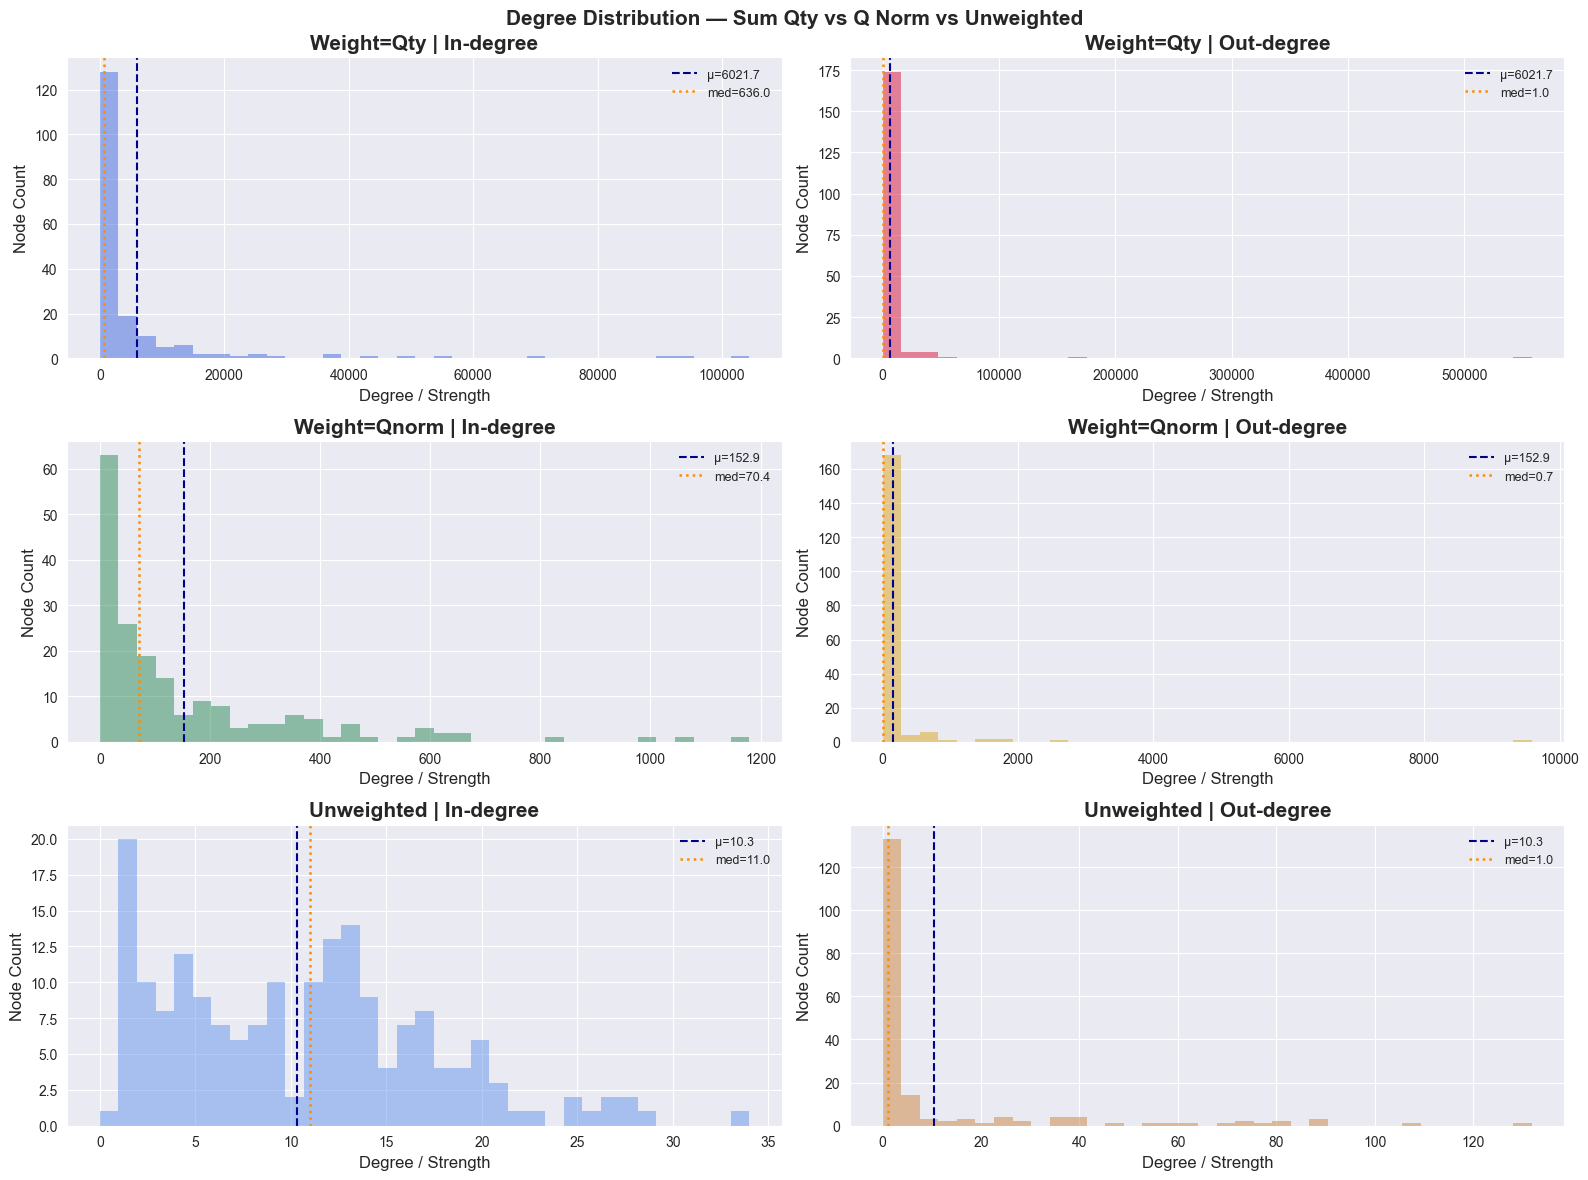

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Degree Distribution — Sum Qty vs Q Norm vs Unweighted', fontsize=15, fontweight='bold')

configs = [
    ('Weight=Qty | In-degree', deg_data['G_qty In'], 'royalblue'),
    ('Weight=Qty | Out-degree', deg_data['G_qty Out'], 'crimson'),
    ('Weight=Qnorm | In-degree', deg_data['G_qnorm In'], 'seagreen'),
    ('Weight=Qnorm | Out-degree', deg_data['G_qnorm Out'], 'goldenrod'),
    ('Unweighted | In-degree', deg_data['G_uw In'], 'cornflowerblue'),
    ('Unweighted | Out-degree', deg_data['G_uw Out'], 'peru'),
]


for ax, (title, data, col) in zip(axes.flat, configs):
    vals = list(data.values())
    ax.hist(vals, bins=35, color=col, edgecolor='none', alpha=0.5)
    ax.axvline(np.mean(vals), color='darkblue', ls='--', lw=1.5, label=f'μ={np.mean(vals):.1f}')
    ax.axvline(np.median(vals), color='darkorange', ls=':', lw=1.8, label=f'med={np.median(vals):.1f}')
    ax.set(title=title, xlabel='Degree / Strength', ylabel='Node Count')
    ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

### 4.1 Heavy-Tail Analysis

we apply **maximum likelihood estimation (MLE)** and a **likelihood ratio (LR) test** using the `powerlaw` package to formally compare candidate distributions:
- **Power-law** vs **Lognormal** fit
- **Power-law** vs **Exponential** fit ( as a baseline — exponential = thin-tailed)

| Result | Interpretation |
|---|---|
| LR > 0, p < 0.05 | Power-law fits **significantly better** |
| LR < 0, p < 0.05 | Lognormal fits **significantly better** |
| p ≥ 0.05 | **Inconclusive** — neither fit is clearly better |

<br>

> The `xmin` parameter (minimum value above which the power-law is fitted) is estimated automatically via the Kolmogorov-Smirnov statistic.


In [15]:
targets = {
    'Weighted In-degree': deg_data['G_qty In'],
    'Weighted Out-degree': deg_data['G_qty Out'],
    'Unweighted In-degree': deg_data['G_uw In'],
    'Unweighted Out-degree': deg_data['G_uw Out'], 
}

results = {}
print(f"{'Distribution':<25} {'α (power-law)':>15} {'xmin':>8} {'LR vs Lognormal':>18} {'p-value':>10} {'Verdict':>15}")
print("-" * 100)

for name, data in targets.items():
    vals = np.array([v for v in data.values() if v > 0])
    fit = powerlaw.Fit(vals, discrete=False, verbose=False)
    # Power-law vs Lognormal
    R_ln, p_ln = fit.distribution_compare('power_law', 'lognormal', normalized_ratio=True)
    # Power-law vs Exponential
    R_ex, p_ex = fit.distribution_compare('power_law', 'exponential', normalized_ratio=True)

    if p_ln < 0.05:
        verdict = 'Power-law' if R_ln > 0 else 'Lognormal'
    else:
        verdict = 'Inconclusive'
    
    results[name] = dict(fit=fit, R_ln=R_ln, p_ln=p_ln, R_ex=R_ex, p_ex=p_ex, verdict=verdict)

    print(f"{name:<25} {fit.power_law.alpha:>15.3f} {fit.xmin:>8.2f} {R_ln:>18.4f} {p_ln:>10.4f} {verdict:>15}")


Distribution                α (power-law)     xmin    LR vs Lognormal    p-value         Verdict
----------------------------------------------------------------------------------------------------
Weighted In-degree                  1.886  3889.00            -1.1610     0.2456    Inconclusive
Weighted Out-degree                 2.121 23170.50            -1.0850     0.2779    Inconclusive
Unweighted In-degree                2.761     8.00            -3.7800     0.0002       Lognormal
Unweighted Out-degree               1.527     1.00            -1.3387     0.1807    Inconclusive


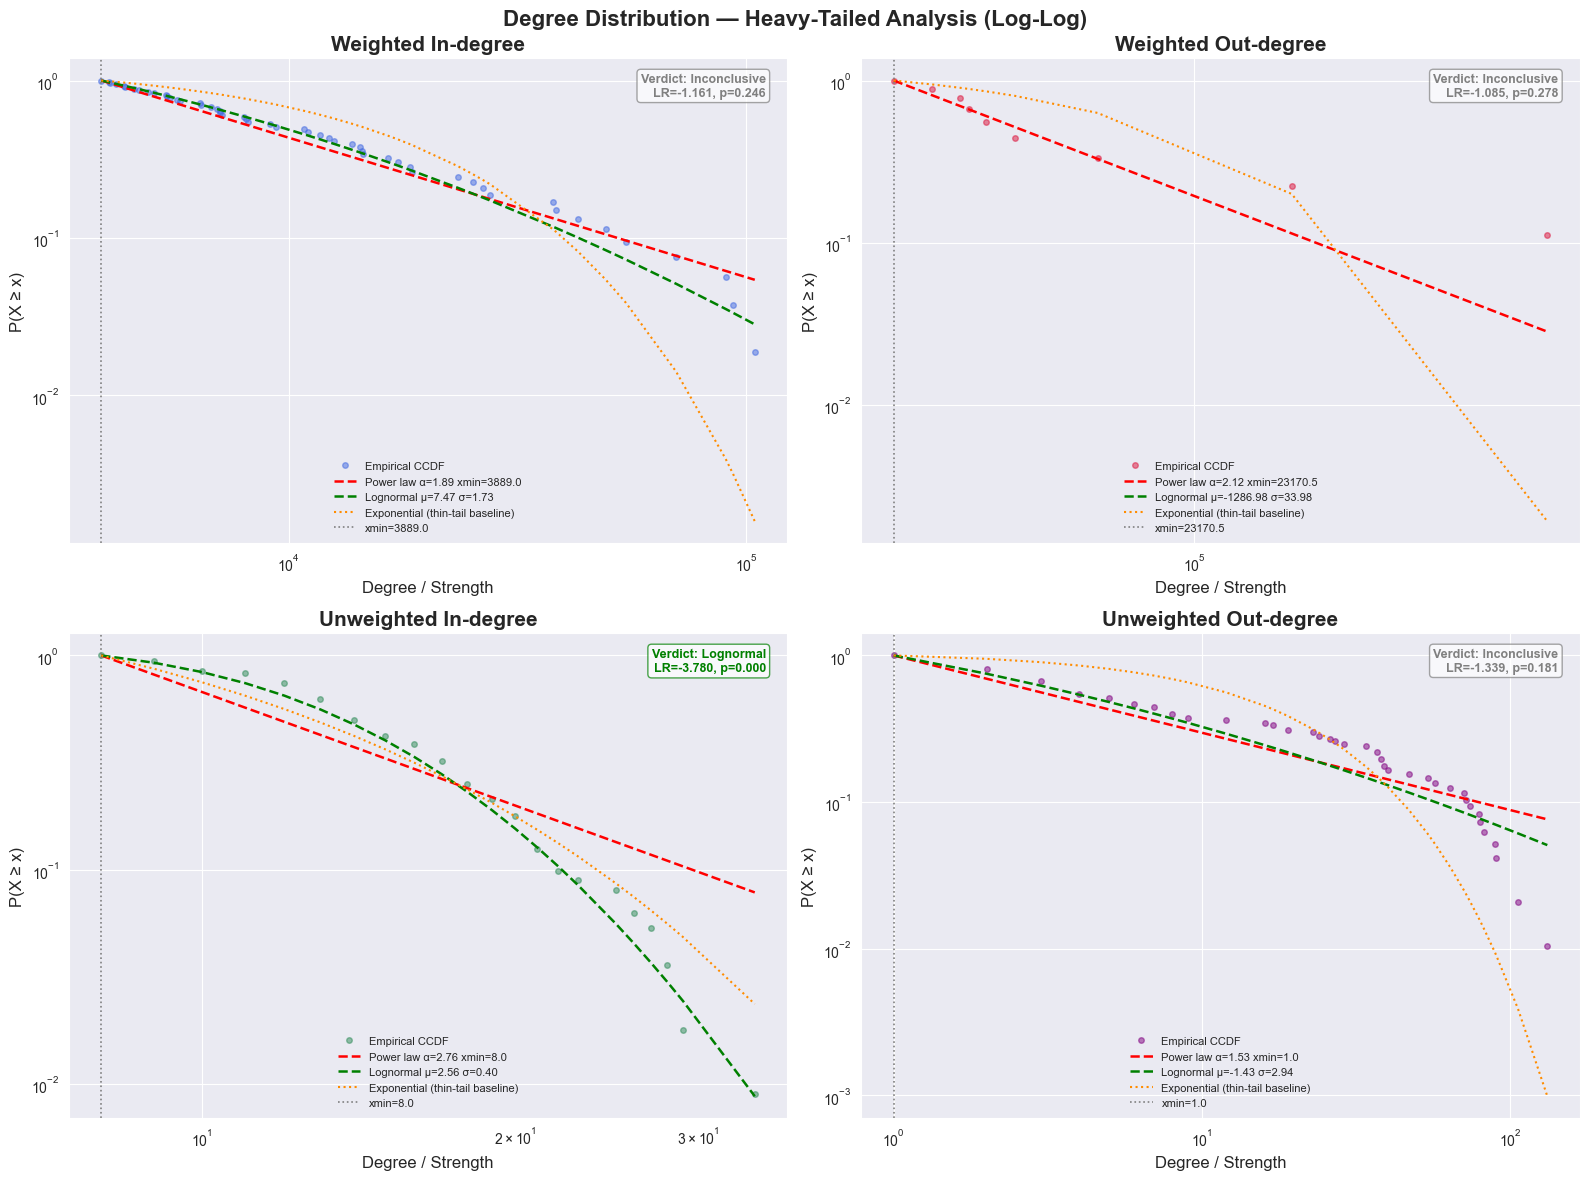

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Degree Distribution — Heavy-Tailed Analysis (Log-Log)', fontsize=16, fontweight='bold')

colors = {'Weighted In-degree': 'royalblue', 'Weighted Out-degree': 'crimson',
          'Unweighted In-degree': 'seagreen', 'Unweighted Out-degree': 'purple'}

for ax, (name, res) in zip(axes.flat, results.items()):
    fit = res['fit']
    col = colors[name]
    vals = np.array([v for v in targets[name].values() if v > 0])

    fit.plot_ccdf(ax=ax, color=col, alpha=0.5, lw=0, marker='o', markersize=4, label='Empirical CCDF')
    fit.power_law.plot_ccdf(ax=ax, color='red', linestyle='--', lw=1.8, 
                            label=f'Power law α={fit.power_law.alpha:.2f} xmin={fit.xmin:.1f}')
    fit.lognormal.plot_ccdf(ax=ax, color='green', linestyle='--', lw=1.8, 
                            label=f'Lognormal μ={fit.lognormal.mu:.2f} σ={fit.lognormal.sigma:.2f}')
    fit.exponential.plot_ccdf(ax=ax, color='darkorange', linestyle=':', lw=1.5, 
                            label='Exponential (thin-tail baseline)')
    ax.axvline(fit.xmin, color='grey', ls=':', lw=1.2, label=f'xmin={fit.xmin:.1f}')

    verdict_color = 'green' if res['verdict'] == 'Lognormal' else \
                    'red' if res['verdict']== 'Power-law' else 'gray'
    ax.text(0.97, 0.97, f"Verdict: {res['verdict']}\nLR={res['R_ln']:.3f}, p={res['p_ln']:.3f}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            color=verdict_color, fontweight='bold',
            bbox=dict(boxstyle='round, pad=0.3', facecolor='white', alpha=0.7, edgecolor=verdict_color))
    ax.set(title=name, xlabel='Degree / Strength', ylabel='P(X ≥ x)')
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

### 🔑 Key Takeaways

- **Clear heavy-tailed behavior:**  
All degree distributions are strongly right-skewed, with a small number of countries accounting for a disproportionate share of trade volume,

- **lognormal over power-law:**   
Formal tests show that a pure power-law is not strongly supported, lognormal provides a better or comparable fit.

- **Export concentration:**  
Weighted out-degree exhibits the most extreme tail → global export volume is highly concentrated among a few dominant suppliers.

- **Expected result for arm trade networks:**  
A lognormal form is more plausible than a pure power-law, as arms trade dynamics are governed by bounded, multiplicative processes influenced by economic capacity, geopolitical constraints, and stochastic variation.

- **Exponential baseline**  
If both power-law and lognormal beat exponential, the network is considered heavy-tailed regardless of which specific distribution wins.

- **Overall implication:**  
The network is **broad in connectivity but highly unequal in volume**, reflecting constrained, multiplicative processes rather than a purely scale-free system.

---

## 5. Clustering Coefficients

Clustering is computed on **undirected projections** to capture triadic relationships in the network.

- **Local clustering** measures how interconnected a node’s neighbors are.
- **Global clustering (transitivity)** is identical for directed and undirected cases, so it is reported only once.

| | Avg Local |
|---|---|
| G_qty (Weighted) | `avg_local_qty` |
| G_qnorm (Normalized) | `avg_local_qnorm` |
| G_uw (Unweighted) | `avg_local_uw` |

- **Unweighted clustering is significantly higher**, indicating that countries often form triangular trade relationships.
- **Weighted clustering (Qty & Qnorm) is near zero**, suggesting that strong trade ties are not mutually interconnected.


In [17]:
G_qty_und = G_qty.to_undirected()
G_qnorm_und = G_qnorm.to_undirected()
G_uw_und = G_uw.to_undirected()

local_clust_qty = nx.clustering(G_qty_und, weight='weight')
local_clust_qnorm = nx.clustering(G_qnorm_und, weight='weight')
local_clust_uw = nx.clustering(G_uw_und)
avg_local_qty = nx.average_clustering(G_qty_und, weight='weight')
avg_local_qnorm = nx.average_clustering(G_qnorm_und, weight='weight')
avg_local_uw = nx.average_clustering(G_uw_und)
global_clust_uw = nx.transitivity(G_uw_und)

print(f"{'Metric':<40} {'Qty':>10} {'Qnorm':>10} {'Unweighted':>12}")
print("-"*78)
print(f"{'Avg Local Clustering':<40} {avg_local_qty:>10.4f} {avg_local_qnorm:>10.4f} {avg_local_uw:>12.4f}")
print()
print(f"{'Global Clustering (Transitivity)':<49} {global_clust_uw:>12.4f}")

Metric                                          Qty      Qnorm   Unweighted
------------------------------------------------------------------------------
Avg Local Clustering                         0.0010     0.0134       0.5504

Global Clustering (Transitivity)                        0.3207


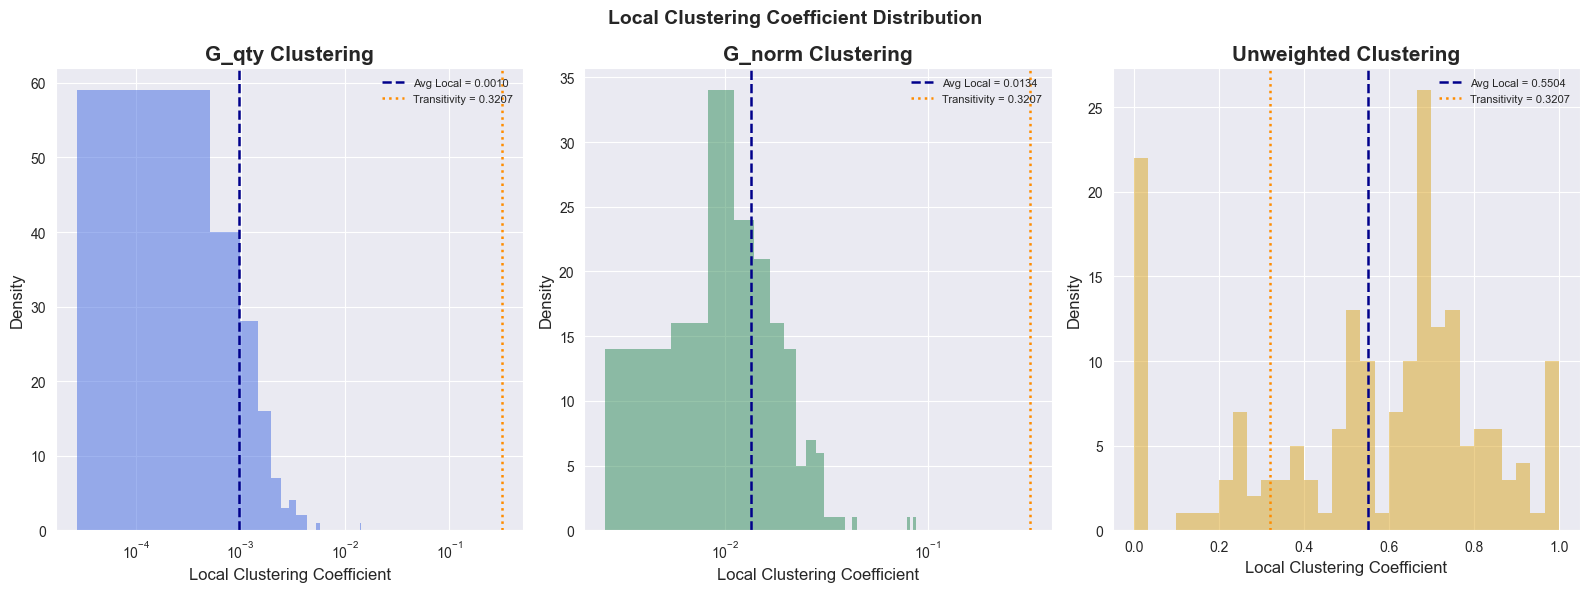

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Local Clustering Coefficient Distribution', fontsize=14, fontweight='bold')

configs = [
    (local_clust_qty, 'G_qty', 'royalblue', avg_local_qty, global_clust_uw),
    (local_clust_qnorm, 'G_norm', 'seagreen', avg_local_qnorm, global_clust_uw),
    (local_clust_uw, 'Unweighted', 'goldenrod', avg_local_uw, global_clust_uw),
]

for ax, (lc, label, col, av, gv) in zip(axes, configs):
    vals = np.array(list(lc.values()))
    if label != 'Unweighted':
        vals = vals[vals > 0]
        ax.set_xscale('log')
    ax.hist(vals, bins=30, color=col, edgecolor='none', alpha=0.5)
    ax.axvline(av, color='darkblue', ls='--', lw=1.8, label=f'Avg Local = {av:.4f}')
    ax.axvline(gv, color='darkorange',  ls=':', lw=1.8, label=f'Transitivity = {gv:.4f}')
    ax.set(title=f'{label} Clustering', xlabel='Local Clustering Coefficient', ylabel='Density')
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

### 🔑 Key Takeaways

- **Strong contrast between weighted vs unweighted clustering:**  
Avg local clustering is extremely low in weighted graphs (Qty: 0.001, Qnorm: 0.0134) but high in unweighted (0.5504).

- **Triangles exist topologically, not economically:**  
Countries are often mutually connected (high unweighted clustering), but strong trade volumes are not reciprocated → weak triadic closure in weighted networks.

- **Normalization slightly increases clustering but remains low:**  
Qnorm raises local clustering compared to Qty, but still indicates sparse strong interconnections.

- **Global clustering (0.3207) is moderate:**  
Suggests that triangles exist at the network level, but are not driven by high-volume trade.

---


## 6. Average Path Length & Diameter

Calculated on the **Largest Strongly Connected Component (LSCC)** —  
the subset of nodes where every country can reach each other through directed paths.

- **Weighted APL** uses a transformed distance:  
$dist = -\log\left(\frac{w}{\max(w)}\right)$
  This maps **strong trade links to short distances** and weak links to longer ones, while preserving relative differences and avoiding zero-distance issues.

- **Unweighted APL** is computed using standard hop distance (number of edges), and reflects the network’s **topological small-world properties**.

<br>

> **Interpretation:**  
> Weighted APL captures efficiency of **strong trade pathways**, while unweighted APL captures **structural connectivity**.

In [19]:
def path_stats(G, weighted=False, zero_threshold=1e-6):
    scc = max(nx.strongly_connected_components(G), key=len)
    G_sub = G.subgraph(scc).copy()

    if weighted:
        max_w = max(d['weight'] for _, _, d in G_sub.edges(data=True))
        for u, v, d in G_sub.edges(data=True):
                w = d['weight'] / max_w
                d['dist'] = -np.log(max(w, zero_threshold))
        lengths = dict(nx.all_pairs_dijkstra_path_length(G_sub, weight='dist'))
        apl  = np.mean([v for src, row in lengths.items() for k, v in row.items() if k != src])
        diam = max([v for src, row in lengths.items() for k, v in row.items() if k != src])
    else:
        apl  = nx.average_shortest_path_length(G_sub)
        diam = nx.diameter(G_sub)
    return apl, diam, len(scc), list(scc)

apl_qty, diam_qty, n_qty, scc_qty = path_stats(G_qty, weighted=True)
apl_qnorm, diam_qnorm, n_qnorm, scc_qnorm = path_stats(G_qnorm, weighted=True)
apl_uw, diam_uw, n_uw, scc_uw = path_stats(G_uw, weighted=False)

print(f"{'Metric':<30} {'G_qty':>12} {'G_qnorm':>12} {'Unweighted':>12}")
print("-"*72)
print(f"{'LSCC Size':<30} {n_qty:>12} {n_qnorm:>12} {n_uw:>12}")
print(f"{'Avg Path Length':<30} {apl_qty:>12.4f} {apl_qnorm:>12.4f} {apl_uw:>12.4f}")
print(f"{'Diameter':<30} {diam_qty:>12.0f} {diam_qnorm:>12.0f} {diam_uw:>12.0f}")

Metric                                G_qty      G_qnorm   Unweighted
------------------------------------------------------------------------
LSCC Size                                77           77           77
Avg Path Length                     17.2110      10.1847       2.3838
Diameter                                 53           31            6


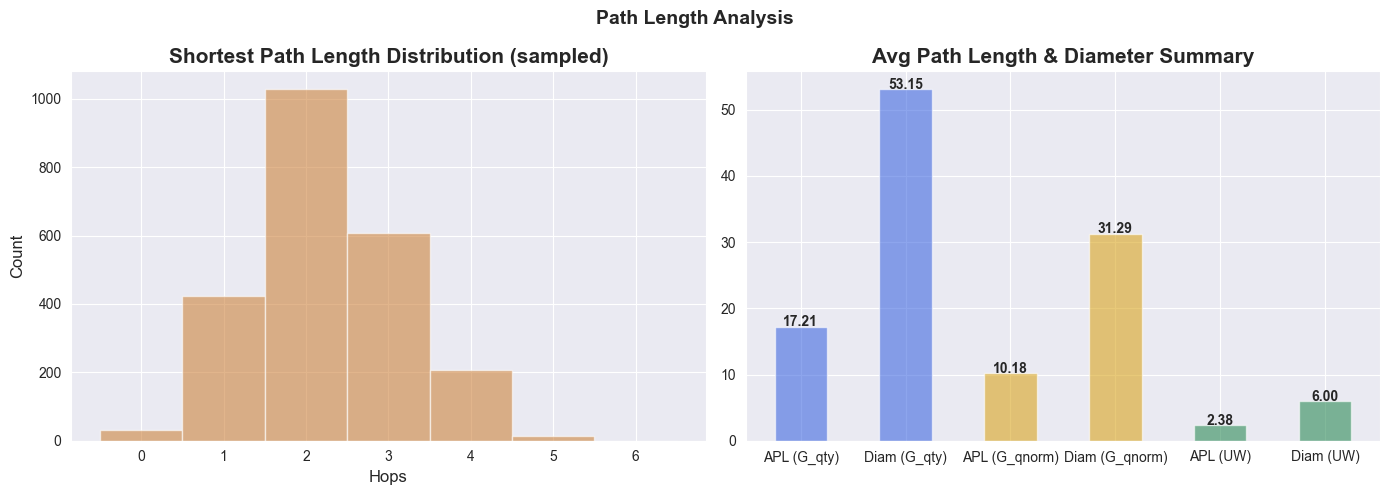

In [20]:
# Path Length Distribution (using sample from unweighted LSCC)
random.seed(42)
sample_nodes = random.sample(scc_uw, min(30, len(scc_uw)))
G_scc = G_uw.subgraph(scc_uw)
path_lengths = []
for src in sample_nodes:
    path_lengths.extend(nx.single_source_shortest_path_length(G_scc, src).values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Path Length Analysis', fontsize=14, fontweight='bold')

axes[0].hist(path_lengths,  bins=range(0, diam_uw+2), color='peru', alpha=0.6, align='left')
axes[0].set(title='Shortest Path Length Distribution (sampled)', xlabel='Hops', ylabel='Count')

metrics = ['APL (G_qty)', 'Diam (G_qty)', 'APL (G_qnorm)', 'Diam (G_qnorm)', 'APL (UW)', 'Diam (UW)']
values = [apl_qty, diam_qty, apl_qnorm, diam_qnorm, apl_uw, diam_uw]
colors_b = ['royalblue', 'royalblue', 'goldenrod', 'goldenrod', 'seagreen', 'seagreen']
bars = axes[1].bar(metrics, values, color=colors_b, alpha=0.6, width=0.5)
for b, v in zip(bars, values):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.05, f'{v:.2f}', ha='center', fontweight='bold')
axes[1].set(title='Avg Path Length & Diameter Summary')

plt.tight_layout()
plt.show()

### 🔑 Key Takeaways

- **Unweighted network is highly efficient:**
Low APL (2.38) and small diameter (6) indicate a **small-world structure**, where countries are only a few steps apart.

- **Weighted distances are much larger:**
APL and diameter increase significantly (Qty ~17 / ~53, Qnorm: ~10 / ~31) reflecting **friction in trade intensity** — strong connections are limited.
*(values computed on directed LSCC, excluding self-distances.)

- **Qnorm reduces extreme distances:**  
Normalization lowers both APL and diameter compared to raw quantities, but the network remains less efficient than unweighted.

- **Same LSCC size (77 nodes):**  
All versions share identical connectivity → differences arise purely from **edge weighting**, not structure.

- **Overall structure:**  
The network is **topologically compact but economically distant**, where countries are structurally close, but strong trade pathways are limited and uneven.

---

## 7. Centrality Measures

Centrality measures capture different dimensions of influence in the arms trade network.

| Centrality | Interpretation |
|---|---|
| **Degree (Unweighted)** | Number of trade partners → structural connectivity |
| **Strength (Weighted Degree)** | Total trade volume → economic influence |
| **Betweenness** | Brokerage role → control over trade pathways between regions |
| **Closeness** | Accessibility → how efficiently a country can reach others |
| **Eigenvector** | Prestige → connection to other influential countries |
| **PageRank** | Directed influence → importance based on incoming connections |
| **Katz** | Global influence → accounts for all direct and indirect connections |

- **Degree vs Strength:** distinguishes between *connectivity* and *actual trade dominance*  
- **Flow-based measures (betweenness, closeness):** capture control and efficiency of trade routes  
- **Spectral measures (eigenvector, PageRank, Katz):** capture influence through network position

> **Key Insight:**  
> Centrality reveals that influence in the network is **multi-dimensional**, where dominant exporters are not only highly connected, but also occupy structurally and strategically central positions.

In [21]:
def compute_centralities(G, weighted=False):
    G_dist = G.copy()
    n = len(G) - 1

    if weighted:
        max_w = max(d['weight'] for _, _, d in G_dist.edges(data=True))
        for u, v, d in G_dist.edges(data=True):
                w = d['weight'] / max_w
                d['dist'] = -np.log(max(w, 1e-6))
    
    G_und = G.to_undirected()
    w_kw = dict(weight='weight') if weighted else {}
    d_kw = dict(weight='dist') if weighted else {}
    c = {
    'in_degree': nx.in_degree_centrality(G),
    'out_degree': nx.out_degree_centrality(G),
    'degree': nx.degree_centrality(G),
    'betweenness': nx.betweenness_centrality(G_dist, normalized=True, **d_kw),
    'closeness': nx.closeness_centrality(G_dist, **({'distance': 'dist'} if weighted else {})),
    'pagerank': nx.pagerank(G, alpha=0.85, **w_kw),
    'katz': nx.katz_centrality_numpy(G, **w_kw),
    }

    try:
        c['eigenvector'] = nx.eigenvector_centrality_numpy(G_und, **w_kw)
    except:
        c['eigenvector'] = nx.eigenvector_centrality(G_und, max_iter=1000, **w_kw)
    
    if weighted:
        c['in_strength'] = {v: s / n for v, s in G.in_degree(weight='weight')}
        c['out_strength'] = {v: s / n for v, s in G.out_degree(weight='weight')}
        c['strength'] = {v: s / n for v, s in G.degree(weight='weight')}
    return c

cent_qty = compute_centralities(G_qty, weighted=True)
cent_qnorm = compute_centralities(G_qnorm, weighted=True)
cent_uw = compute_centralities(G_uw, weighted=False)
print('All Centralities computed.')

All Centralities computed.


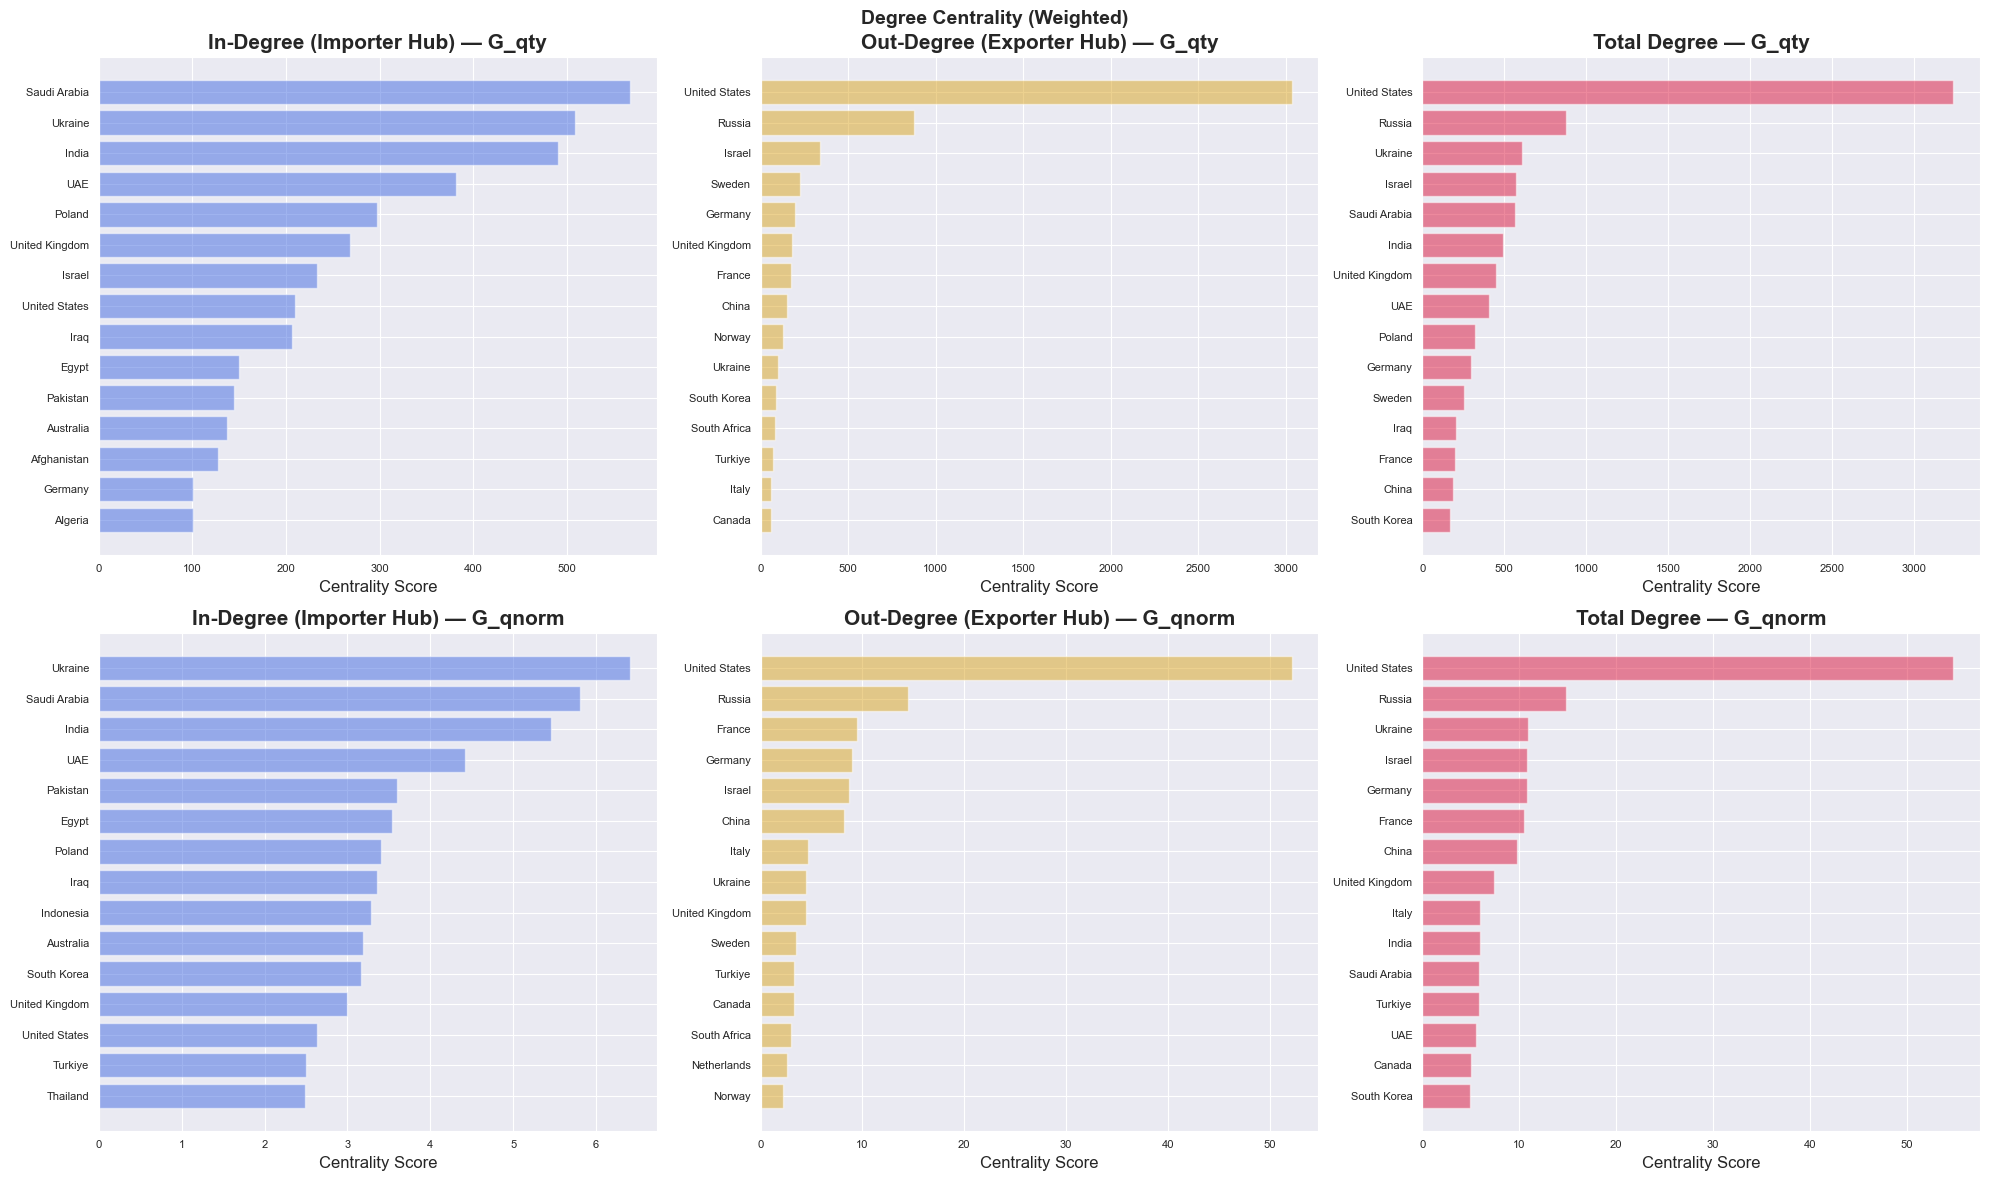

In [22]:
# Degree Centrality (In/Out/Total) — Weighted
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Degree Centrality (Weighted)', fontsize=14, fontweight='bold')

metrics = [
    ('in_strength', 'In-Degree (Importer Hub)', 'royalblue'),
    ('out_strength', 'Out-Degree (Exporter Hub)', 'goldenrod'),
    ('strength', 'Total Degree', 'crimson'),
]
for row, (cent, label) in enumerate([(cent_qty, 'G_qty'), (cent_qnorm, 'G_qnorm')]):
    for col, (key, title, color) in enumerate(metrics):
        ax = axes[row, col]
        top = sorted(cent[key].items(), key=lambda x: x[1], reverse=True)[:15]
        ns, vs = zip(*top)
        ax.barh(list(ns)[::-1], list(vs)[::-1], color=color, alpha=0.5)
        ax.set(title=f'{title} — {label}', xlabel='Centrality Score')
        ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

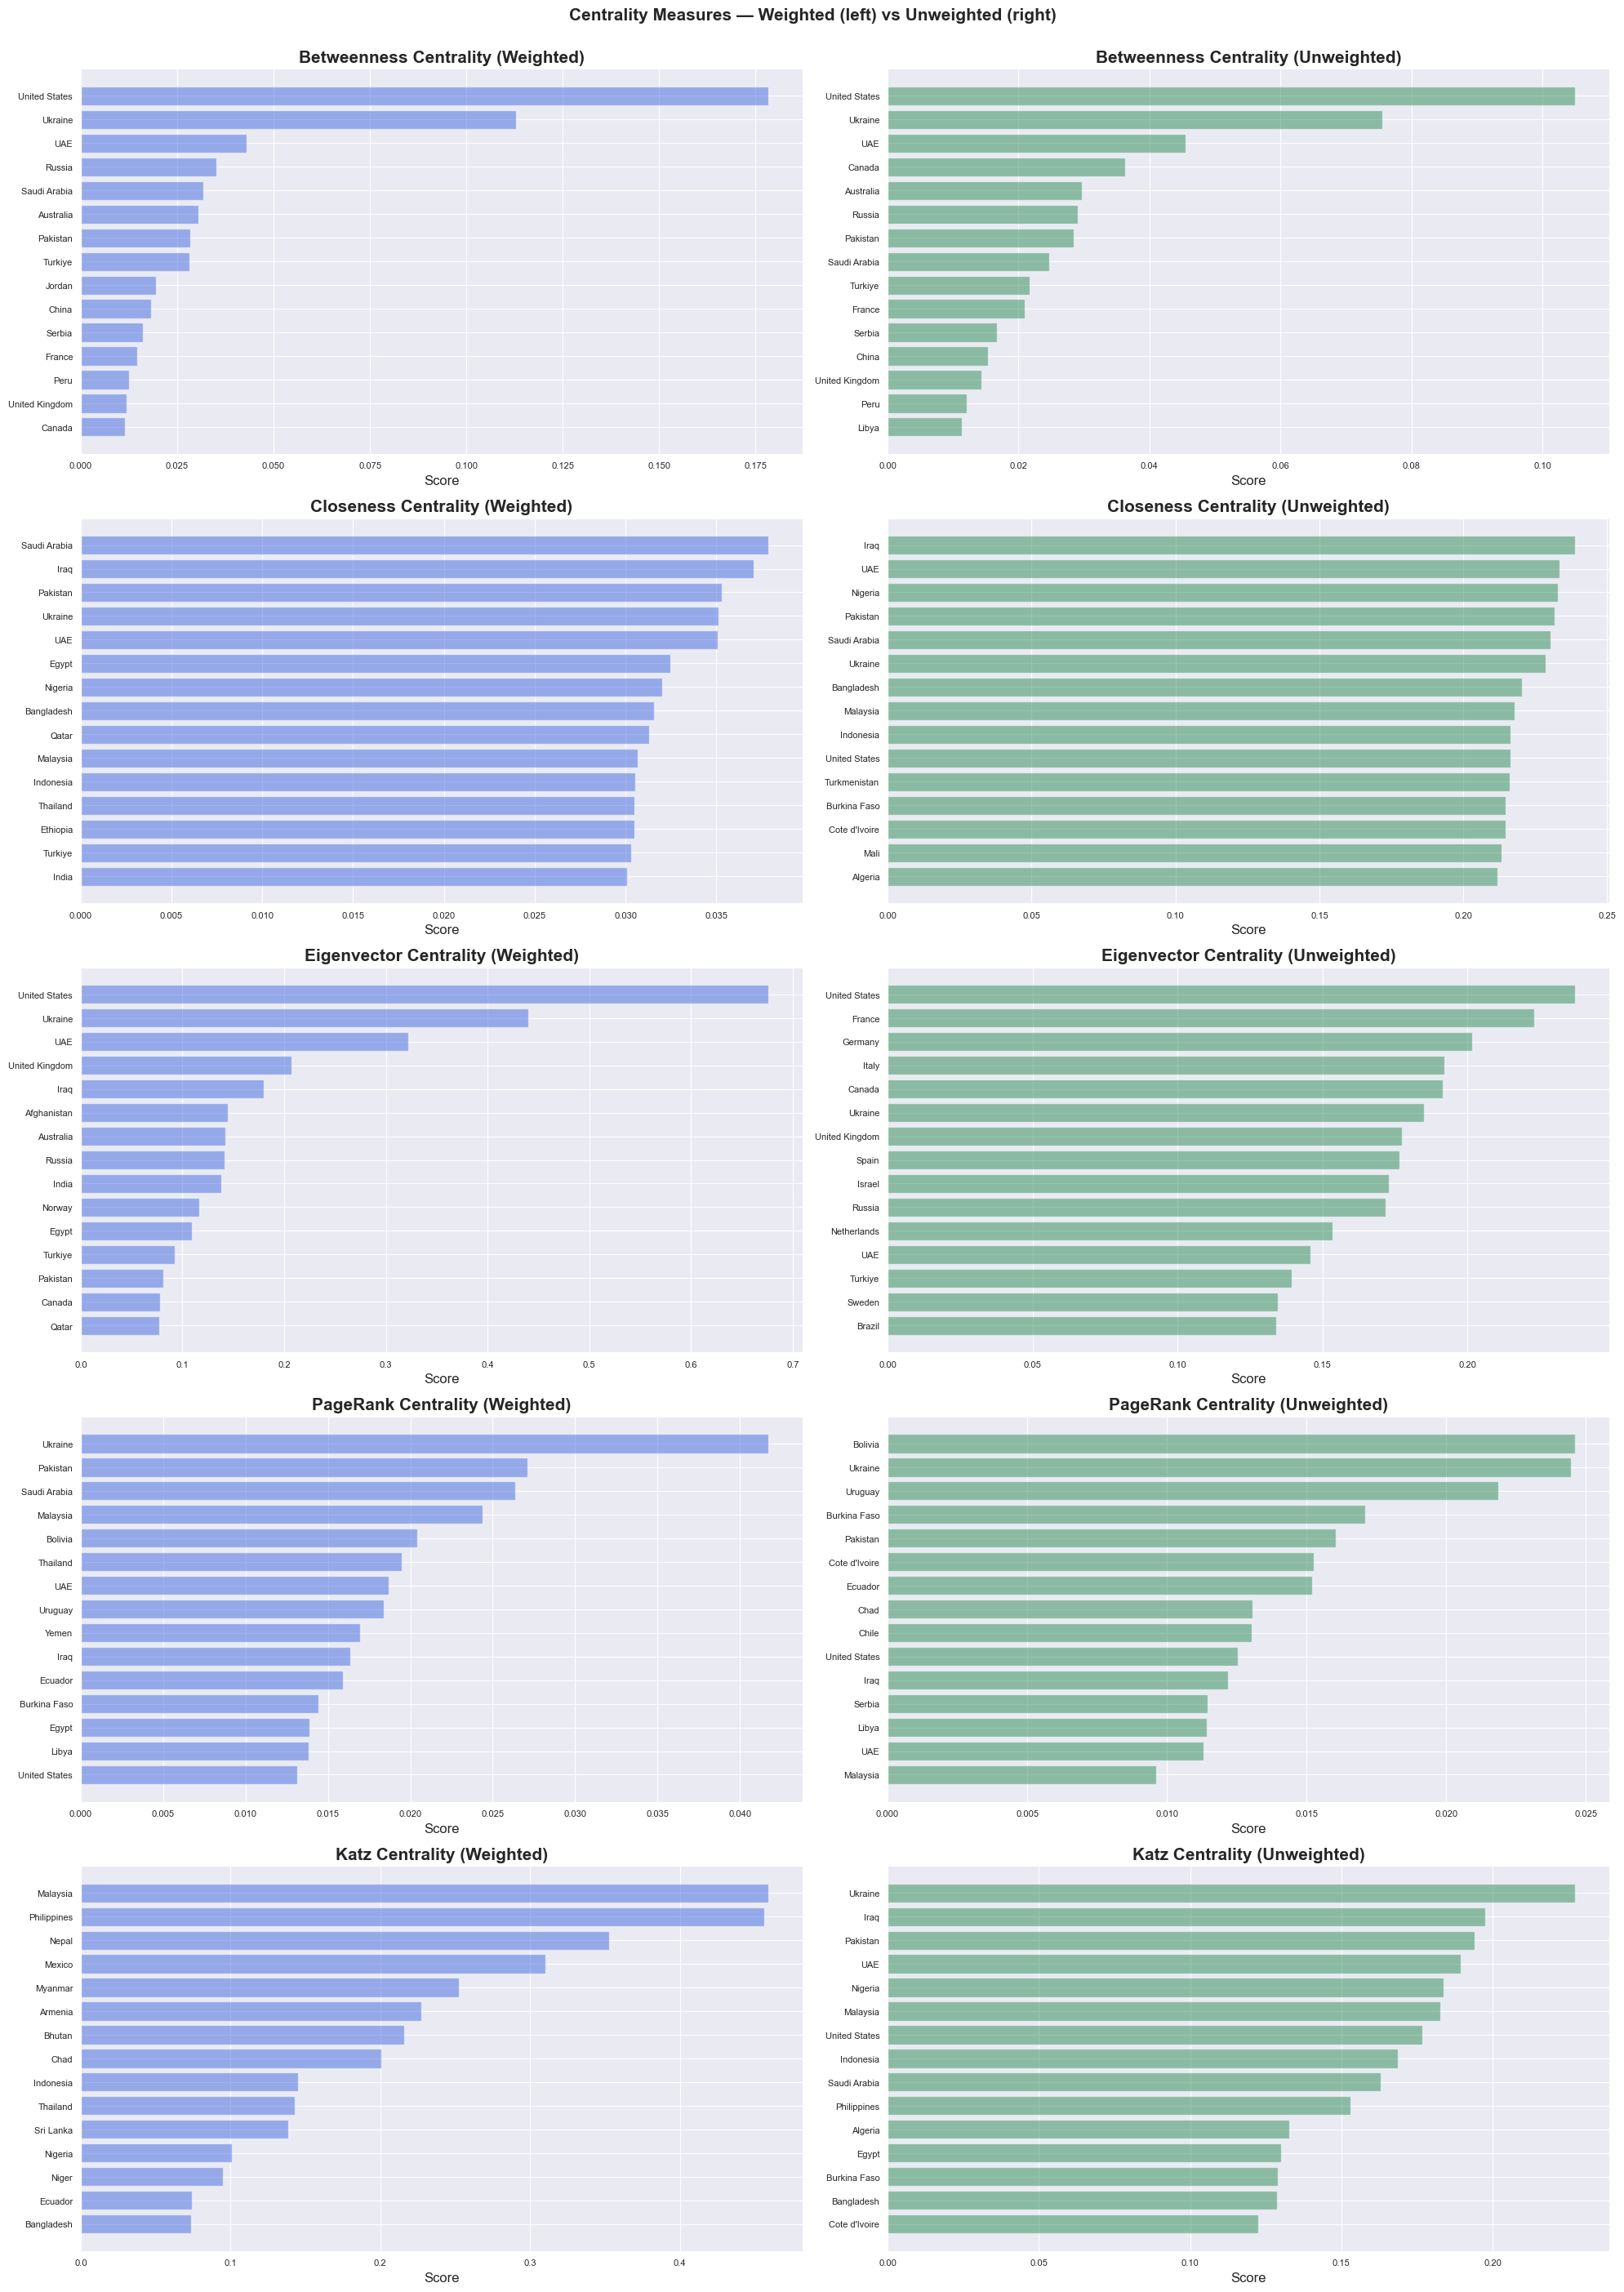

In [23]:
# Betweenness, Closeness, Eigenvector, PageRank, Katz
cent_keys = ['betweenness','closeness','eigenvector','pagerank','katz']
cent_labels = ['Betweenness','Closeness','Eigenvector','PageRank','Katz']

fig, axes = plt.subplots(len(cent_keys), 2, figsize=(20, 28))
fig.suptitle('Centrality Measures — Weighted (left) vs Unweighted (right)',
             fontsize=15, fontweight='bold', y=1.001)
for i, (key, lbl) in enumerate(zip(cent_keys, cent_labels)):
    for j, (cent_d, col, wlbl) in enumerate([
        (cent_qty, 'royalblue','Weighted'),
        (cent_uw, 'seagreen', 'Unweighted'),
    ]):
        ax = axes[i, j]
        top = sorted(cent_d[key].items(), key=lambda x: x[1], reverse=True)[:15]
        ns, vs = zip(*top)
        ax.barh(list(ns)[::-1], list(vs)[::-1], color=col, alpha=0.5)
        ax.set(title=f'{lbl} Centrality ({wlbl})', xlabel='Score')
        ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

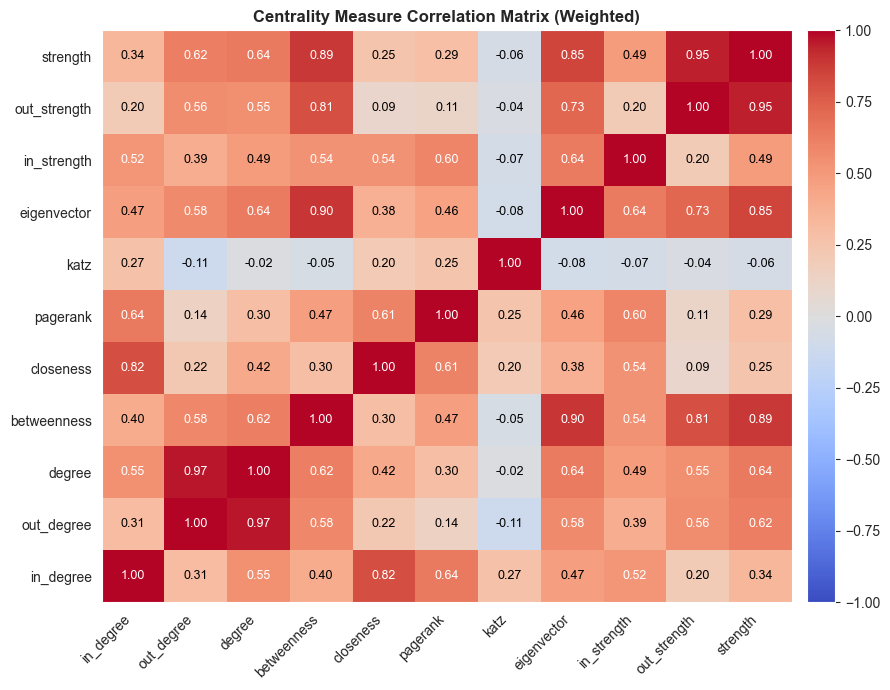

In [24]:
# Centrality correlation heatmap
cent_df = pd.DataFrame({k: cent_qty[k] for k in cent_qty}).fillna(0)
corr = cent_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.pcolormesh(corr.values, cmap='coolwarm', vmin=-1, vmax=1, shading='nearest')
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center',
                fontsize=9, color='black' if abs(corr.values[i,j]) < 0.5 else 'white')
ax.set_title('Centrality Measure Correlation Matrix (Weighted)', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
plt.tight_layout()
plt.show()

In [25]:
# Top-20 ranking table
ranking = pd.DataFrame({
    'PageRank': cent_qty['pagerank'],
    'Betweenness': cent_qty['betweenness'],
    'Eigenvector': cent_qty['eigenvector'],
    'Katz': cent_qty['katz'],
    'Closeness': cent_qty['closeness'],
}).sort_values('PageRank', ascending=False).head(20).round(5)
print("Top 20 countries by weighted PageRank:")
ranking

Top 20 countries by weighted PageRank:


,PageRank,Betweenness,Eigenvector,Katz,Closeness
Ukraine,0.04173,0.11279,0.44007,-0.00011,0.03511
Pakistan,0.02709,0.02836,0.08124,0.00166,0.03532
Saudi Arabia,0.02636,0.03172,0.02807,-0.01029,0.03787
Malaysia,0.02440,0.00546,0.00756,0.45914,0.03065
Bolivia,0.02043,0.00000,0.00022,0.00529,0.02388
Thailand,0.01949,0.00113,0.01898,0.14278,0.03050
UAE,0.01867,0.04309,0.32189,0.00019,0.03508
Uruguay,0.01841,0.00015,0.00048,-0.00149,0.02398
Yemen,0.01697,0.00000,0.00272,-0.04929,0.02851
Iraq,0.01637,0.00000,0.18015,-0.11852,0.03706


### 🔑 Key Takeaways

- **Multi-dimensional influence:**  
No single country dominates all metrics → influence varies by role (exporter, broker, prestige, accessibility).

- **United States = structural & strategic hub:**  
Highest betweeness and eigenvector → central broker connecting major players and embedded in the core network.

- **Ukraine = flow-central node:**  
Highest PageRank → receives connections from many high-importance countries. This result is likely driven by large post-2022 inflows from major exporters (US, Germany, UK, and other NATO members). In a directed Graph, PageRank accumulates via incoming links from influential senders, Ukraine's score is strongly elevated.

- **Export dominance ≠ PageRank dominance:**  
Major Exporters (e.g., US, Russia) dominates degree/strength, but PageRank highlights **active flow participation**, not just volume.
 
- **Closeness favors mid-network countries**  
Countries like Saudi Arabia, Iraq, Pakistan → positioned efficiently within the network rather than being dominant hubs.

- **Katz highlights diffuse/global influence:**  
Countries like Malaysia rank high despite low direct power → influence through indirect connections.

- **Correlation insights:**    
  - Degree ↔ Strength are highly correlated → connectivity aligns with volume  
  - Betweenness ↔ Eigenvector also strongly linked → brokers tend to connect to influential nodes  
  - Katz behaves differently → captures alternative, long-range influence patterns

- **Overall structure:**  
  The network exhibits **layered centrality**:
  - **Core hubs:** US, Russia, France — high in strength, betweenness, and eigenvector
  - **Flow-active nodes:** Ukraine, Pakistan — high PageRank from important incoming sources.
  - **Peripheral but connected actors:** many smaller countries

---

## 8. Network Visualisations

Visualizations focus on the **top 60 countries by weighted degree (strength)** to ensure clarity while preserving the core structure of the network.

| Visual Element | Interpretation |
|---|---|
| **Node size** | ∝ PageRank → importance based on flow participation |
| **Node color** | Community (geopolitical blocs) from modularity detection |
| **Edge thickness** | ∝ trade volume → strength of arms transfer |
| **Edge direction** | Exporter → Importer (flow of arms) |

- The visualization highlights the **core-periphery structure**, where a few dominant hubs connect many peripheral countries.
- Community coloring reveals **geopolitical clustering** within the top-60 subgraph, often reflecting regional or strategic alliances.
- Node size emphasizes **flow-based importance**, which may differ from pure export volume.

> **Key Insight:**  
> The network exhibits a **hub-and-spoke structure with clustered blocs**, where influence is concentrated in key hubs but organized into distinct geopolitical communities.

In [26]:
from networkx.algorithms.community import greedy_modularity_communities

TOP_N = 60
BLOC_PALETTE = ['royalblue', 'indianred', 'mediumseagreen',
                'goldenrod', 'mediumpurple', 'peru',
                'cornflowerblue', 'salmon']

top_nodes = sorted(G_qty.nodes(), key=lambda n: G_qty.degree(n, weight='weight'), reverse=True)[:TOP_N]
G_vis = G_qty.subgraph(top_nodes).copy()

communities_vis = list(greedy_modularity_communities(G_vis.to_undirected(), weight='weight'))
node_community = {node: idx for idx, comm in enumerate(communities_vis) for node in comm}

pr_vis = nx.pagerank(G_vis, weight='weight', alpha=0.85)
pr_vals = np.array([pr_vis[n] for n in G_vis.nodes()])
pr_norm = (pr_vals - pr_vals.min()) / (pr_vals.max() - pr_vals.min() + 1e-9)

node_colors = [BLOC_PALETTE[node_community.get(n,0) % len(BLOC_PALETTE)] for n in G_vis.nodes()]
node_sizes = [250 + 3500 * pr_norm[i] for i in range(len(G_vis.nodes()))]

ew = [G_vis[u][v]['weight'] for u,v in G_vis.edges()]
mw = max(ew)
edge_widths = [0.3 + 2.5 * (w/mw) for w in ew]

print("Computing layouts...")
layouts = {
    'Circular': nx.circular_layout(G_vis),
    'Spring': nx.spring_layout(G_vis, weight='weight', seed=42, k=0.7),
    'Kamada-Kawai': nx.kamada_kawai_layout(G_vis, weight='weight'),
    'Spectral': nx.spectral_layout(G_vis, weight='weight')
}
print("Done.")

Computing layouts...
Done.


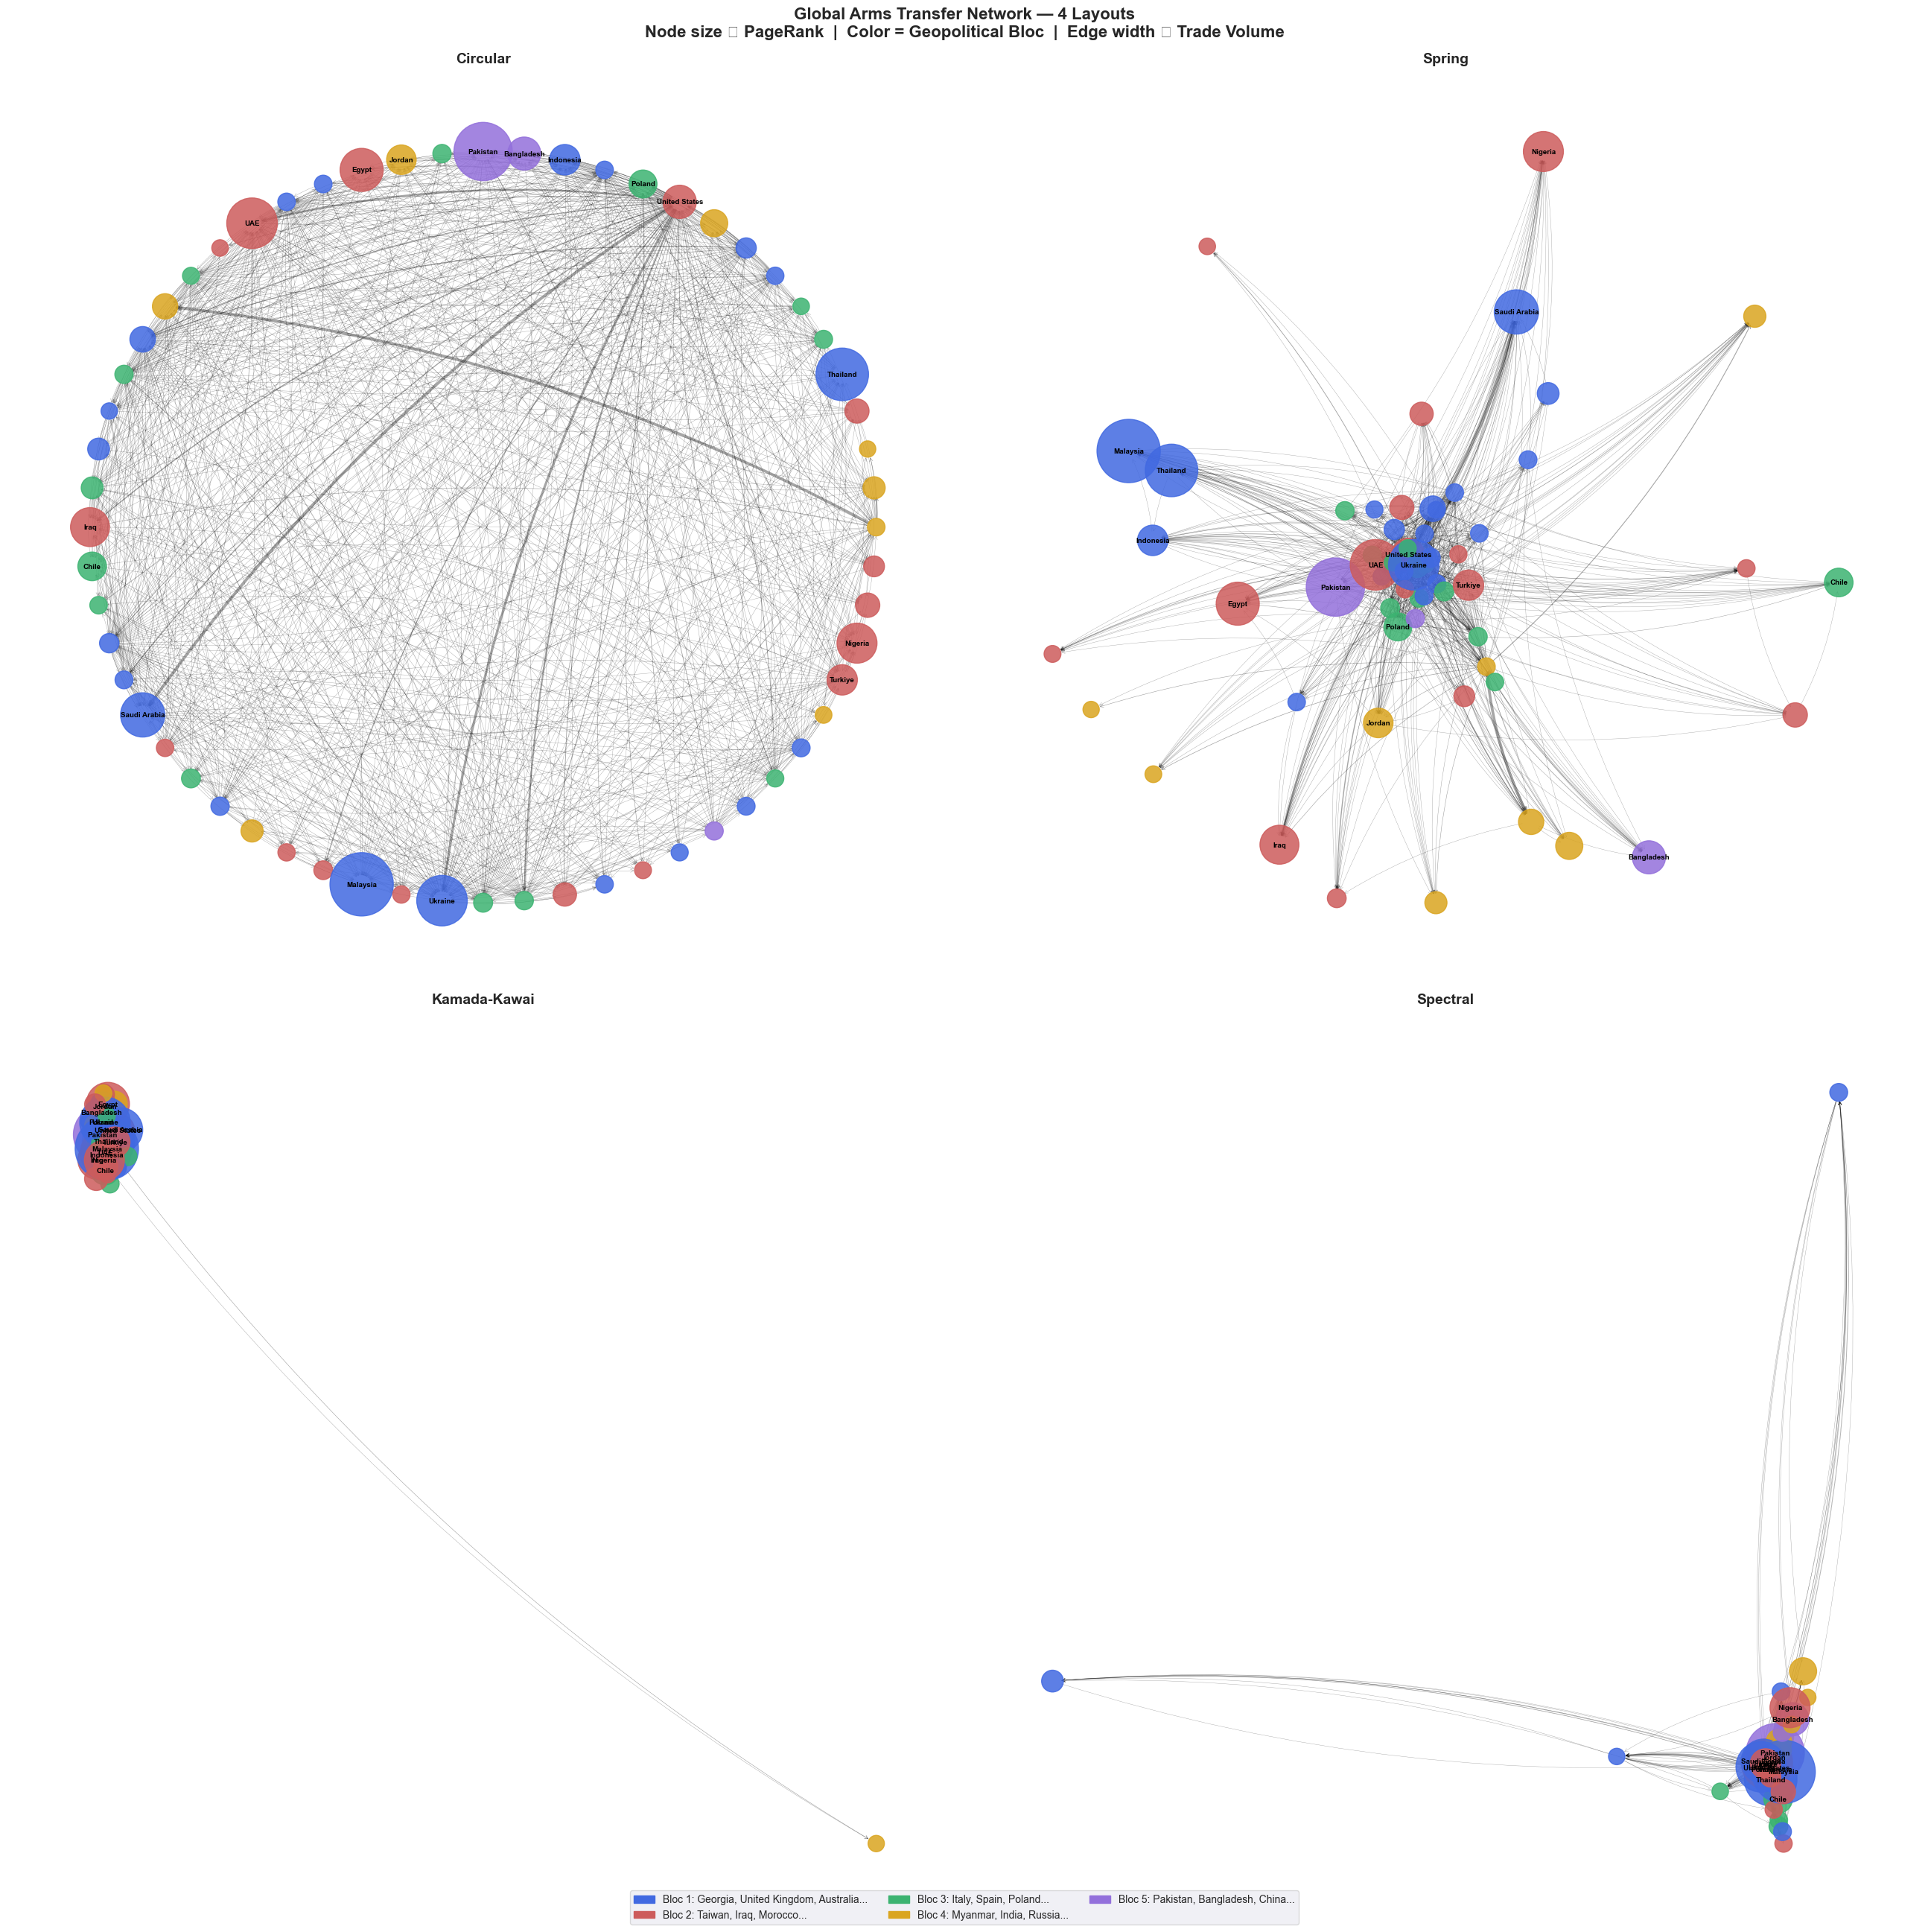

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(26, 26))
fig.suptitle(
    'Global Arms Transfer Network — 4 Layouts\n'
    'Node size ∝ PageRank  |  Color = Geopolitical Bloc  |  Edge width ∝ Trade Volume',
    fontsize=16, fontweight='bold', y=0.995)

for ax, (title, pos) in zip(axes.flat, layouts.items()):
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    nx.draw_networkx_edges(G_vis, pos, ax=ax,
        width=edge_widths, alpha=0.35, edge_color='black',
        arrows=True, arrowstyle='->', arrowsize=8,
        connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_nodes(G_vis,  pos, ax=ax,
        node_color=node_colors, node_size=node_sizes, alpha=0.85)
    big = {n for n, s in zip(G_vis.nodes(), node_sizes) if s > 700}
    nx.draw_networkx_labels(G_vis, pos, labels={n: n for n in big},
        ax=ax, font_size=7, font_weight='bold')
    ax.axis('off')

bloc_names = [f'Bloc {i+1}: {", ".join(list(c)[:3])}...' for i, c in enumerate(communities_vis)]
handles = [mpatches.Patch(color=BLOC_PALETTE[i % len(BLOC_PALETTE)], label=bloc_names[i])
           for i in range(len(communities_vis))]
fig.legend(handles=handles, loc='lower center',  ncol=3, fontsize=10,
           framealpha=0.7, bbox_to_anchor=(0.5, 0.002))
plt.tight_layout()
plt.show()

### 🔑 Key Takeaways

- **Clear hub-and-spoke structure:**  
A few dominant exporters form the core, connecting many peripheral countries → strong centralization of arms trade.

- **Core–periphery pattern:**  
The central cluster is dense and interconnected, while outer countries depend on key hubs for access.

- **Consistent structure across layouts:**  
Core hubs and clusters remain visible across Circular, Spring, Kamada-Kawai, and Spectral layouts → structure is robust.

- **Geopolitical clustering is evident:**  
Communities (node colors) reflect regional or strategic alliances in arms trade.

- **Node size reflects flow importance (PageRank):**  
Larger nodes (e.g., Malaysia, Pakistan) indicate countries that receive connections from important partners, not necessarily the largest exporters.

- **Export dominance vs flow importance:**  
Major exporters like the United States dominate in volume and connectivity, but appear smaller because PageRank emphasizes **incoming influence rather than outgoing supply**.

- **Overall structure:**  
The network is **centralized and modular**, where trade is dominated by key exporters but influence is shaped by both **volume and position within the network**.

---

## 9. Community Detection & Geopolitical Blocs

Communities are detected using **Greedy Modularity Maximization** on the full network.

- The algorithm partitions the network into groups that maximize **modularity (Q)**.
- **Modularity** measures how much more densely connected nodes are within communities compared to a random network.

A higher Q indicates stronger and more meaningful community structure.

> In this context, communities represent **geopolitical blocs**, where countries are more closely connected through arms trade relationships.

In [28]:
from networkx.algorithms.community.quality import modularity

results = {}
for name, G in [('G_qty', G_qty), ('G_qnorm', G_qnorm)]:
    G_und = G.to_undirected()
    communities = sorted(greedy_modularity_communities(G_und, weight='weight'), key=len, reverse=True)
    pr = nx.pagerank(G, weight='weight', alpha=0.85)
    mod_score = modularity(G_und, communities, weight='weight')

    results[name] = dict(communities=communities, pr=pr, mod_score=mod_score)

    print(f"{'='*60}")
    print(f"{name}  |  Communities: {len(communities)}  |  Modularity: {mod_score:.4f}")
    print(f"{'='*60}")

    for i, comm in enumerate(communities[:6]):
        top = sorted(comm, key=lambda n: pr.get(n, 0), reverse=True)[:10]
        print(f"  Bloc {i+1} ({len(comm)} nations): {', '.join(top)}")
    print()

communities_qty = results['G_qty']['communities']
communities_qnorm = results['G_qnorm']['communities'] 

G_qty  |  Communities: 5  |  Modularity: 0.3450
  Bloc 1 (68 nations): Ukraine, Thailand, UAE, Iraq, Burkina Faso, Egypt, United States, Niger, Nigeria, Mexico
  Bloc 2 (34 nations): Uruguay, Ecuador, Philippines, Chile, Poland, El Salvador, Finland, Denmark, Czechia, Colombia
  Bloc 3 (31 nations): Pakistan, Malaysia, Bolivia, Sudan, Bangladesh, South Sudan, Sri Lanka, Nepal, Cambodia, China
  Bloc 4 (28 nations): Yemen, India, Myanmar, Western Sahara, Armenia, Azerbaijan, Syria, Russia, Algeria, Uganda
  Bloc 5 (24 nations): Saudi Arabia, Libya, Chad, Cote d'Ivoire, Georgia, Indonesia, Angola, Serbia, Guinea, France

G_qnorm  |  Communities: 3  |  Modularity: 0.2541
  Bloc 1 (68 nations): Bolivia, Pakistan, Burkina Faso, Cote d'Ivoire, Libya, Yemen, Nigeria, Sudan, Myanmar, India
  Bloc 2 (62 nations): Iraq, UAE, United States, Bahrain, Turkiye, Egypt, Niger, Australia, El Salvador, Mexico
  Bloc 3 (55 nations): Ukraine, Uruguay, Ecuador, Saudi Arabia, Chad, Malaysia, Thailand, Chile

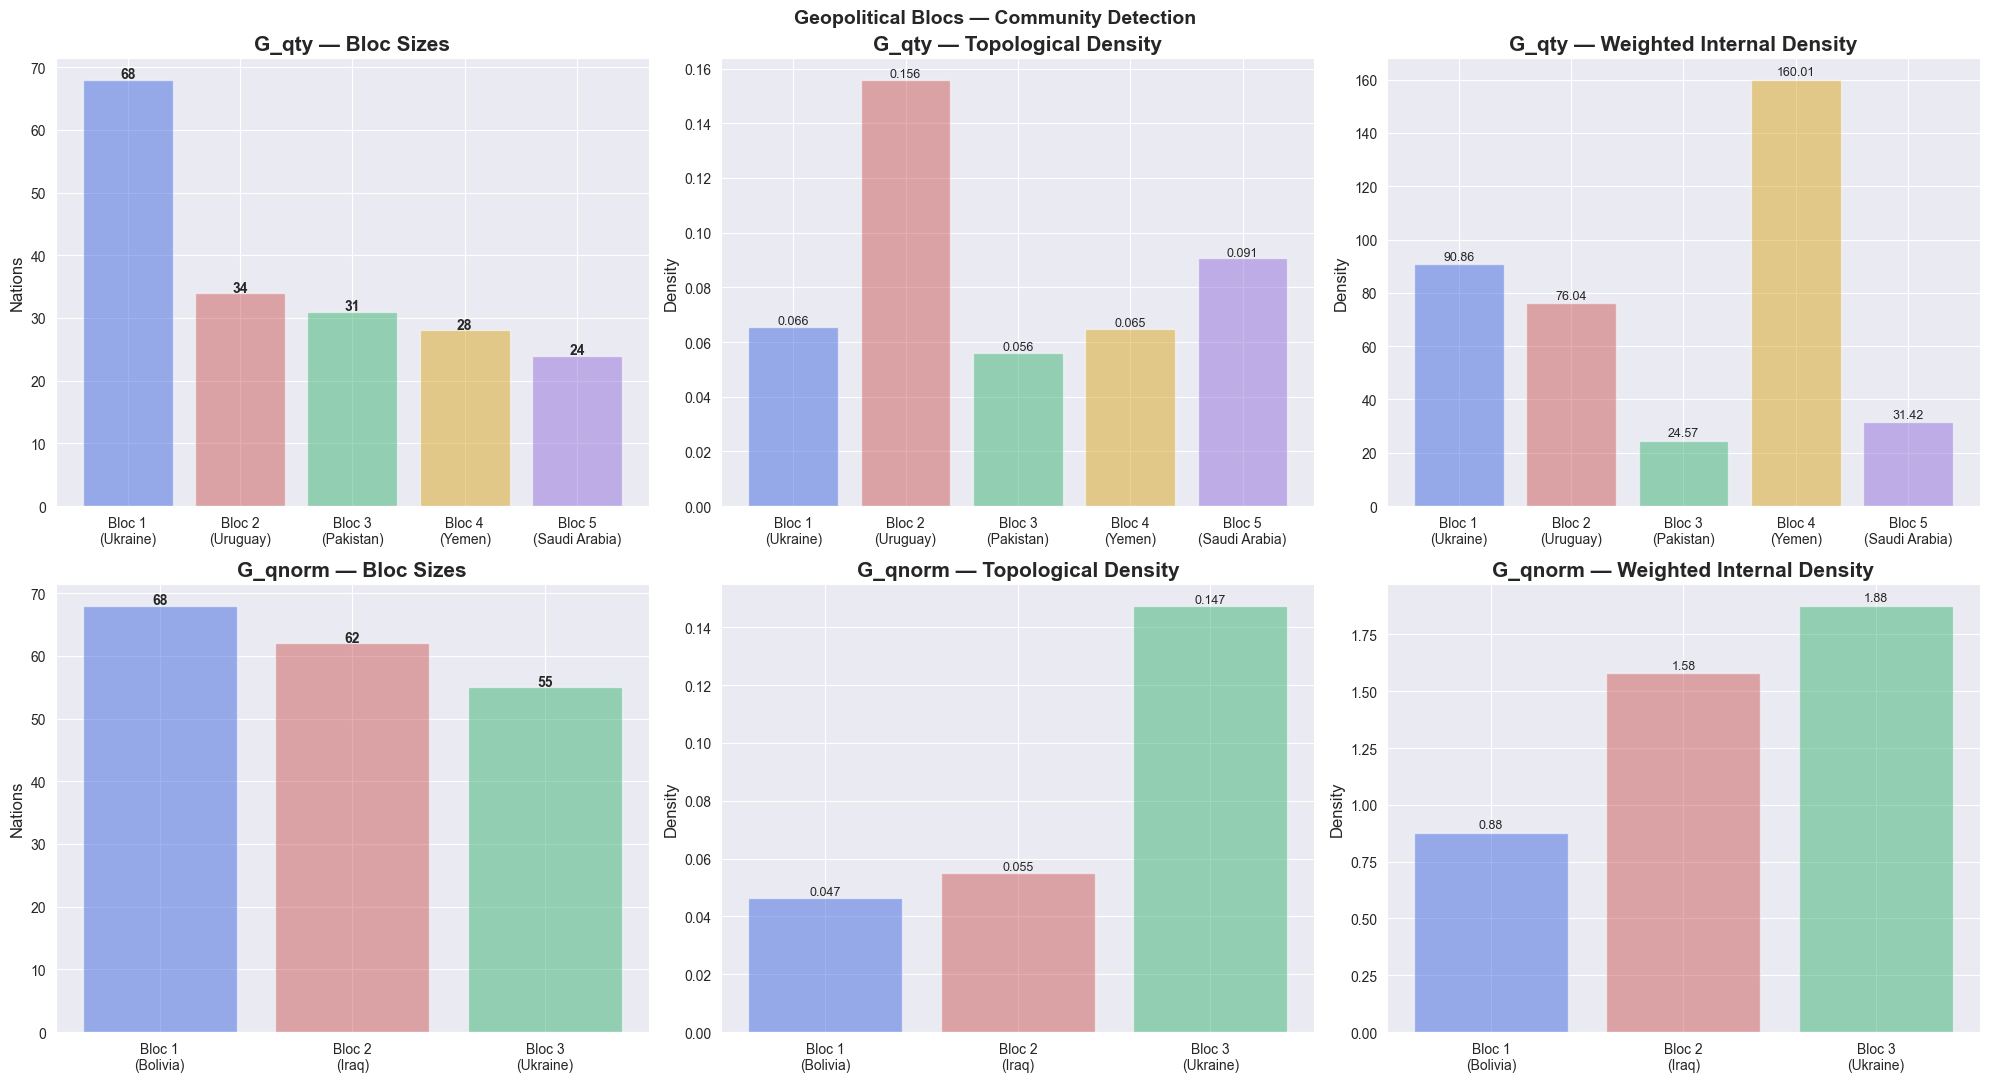

In [29]:
def bloc_stats(G, communities, n=8):
    pr = nx.pagerank(G, weight='weight', alpha=0.85)
    rows = []
    for i, comm in enumerate(communities[:n]):
        sub = G.subgraph(comm)
        top_node = max(comm, key=lambda node: pr.get(node, 0))
        w_den = sum(d['weight'] for _, _, d in sub.edges(data=True))
        rows.append({
            'label': f'Bloc {i+1}',
            'size': len(comm),
            'density': nx.density(sub),
            'w density': w_den / (len(comm) * (len(comm) - 1)) if len(comm) > 1 else 0,
            'top_node': top_node,
        })
    return rows

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle('Geopolitical Blocs — Community Detection', fontsize=14, fontweight='bold')

metrics = [
    ('G_qty', G_qty, communities_qty),
    ('G_qnorm', G_qnorm, communities_qnorm),
]

for ax, (name, G, comm) in zip(axes, metrics):
    stats = bloc_stats(G, comm)
    labels = [f"{s['label']}\n({s['top_node']})" for s in stats]
    colors = BLOC_PALETTE[:len(stats)]

    sizes = [s['size'] for s in stats]
    ax[0].bar(labels, sizes, color=colors, alpha=0.5)
    ax[0].set(title=f"{name} — Bloc Sizes", ylabel='Nations')
    for i, v in enumerate(sizes):
        ax[0].text(i, v + 0.2, str(v), ha='center', fontsize=10, fontweight='bold')
    
    dens = [s['density'] for s in stats]
    ax[1].bar(labels, dens, color=colors, alpha=0.5)
    ax[1].set(title=f"{name} — Topological Density", ylabel='Density')
    for i, v in enumerate(dens):
        ax[1].text(i, v + 0.001, f'{v:.3f}', ha='center', fontsize=9)
    
    wdens = [s['w density'] for s in stats]
    ax[2].bar(labels, wdens, color=colors, alpha=0.5)
    ax[2].set(title=f"{name} — Weighted Internal Density", ylabel='Density')
    for i, v in enumerate(wdens):
        ax[2].text(i, v + max(wdens)*0.01, f'{v:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

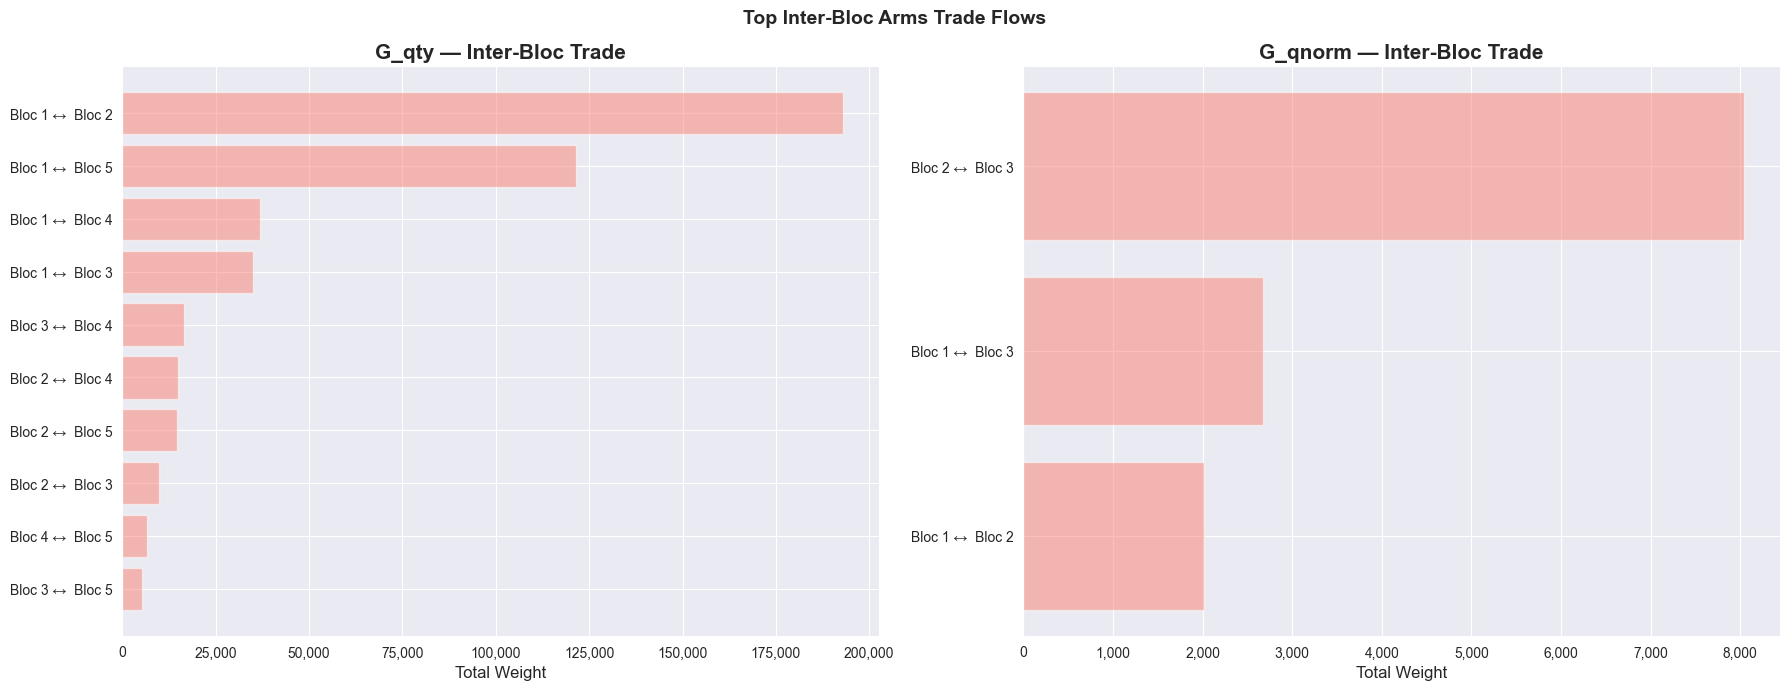

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top Inter-Bloc Arms Trade Flows', fontsize=14, fontweight='bold')

metrics = [
    ('G_qty', G_qty, communities_qty),
    ('G_qnorm', G_qnorm, communities_qnorm),
]

for ax, (name, G, comm) in zip(axes, metrics):
    node_comm = {node: idx for idx, c in enumerate(comm) for node in c}

    inter_bloc = {}
    for u, v, d in G.edges(data=True):
        cu, cv  = node_comm.get(u, -1), node_comm.get(v, -1)
        if cu != cv and cu < 6 and cv < 6:
            key = (min(cu, cv), max(cu, cv))
            inter_bloc[key] = inter_bloc.get(key, 0) + d['weight']
    
    top = sorted(inter_bloc.items(), key=lambda x: x[1], reverse=True)
    labels = [f'Bloc {a+1} ↔  Bloc {b+1}' for (a, b), _ in top][::-1]
    vals = [v for _, v in top][::-1]

    ax.barh(labels, vals, color='salmon', alpha=0.5)
    ax.set(title=f'{name} — Inter-Bloc Trade', xlabel='Total Weight')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

### 🔑 Key Takeaways

- **Moderate modular structure (G_qty, Q = 0.345):**  
The network exhibits **meaningful but overlapping blocs**, indicating structured yet globally interconnected arms trade,

- **Volume-driven fragmentation (5 blocs in G_qty):**   
Real trade volume reveal more distinct geopolitical groupings, with blocs reflecting **regional and strategic dependencies**.

- **Normalization merges communities (3 blocs in G_qnorm, Q = 0.254):**    
Fewer and larger blocs arise because normalization reduces differences in edge weights, making community boundaries less distinct and weakening modular structure.

- **Uneven bloc sizes:**    
A dominant bloc (68 nations) coexists with smaller groups, indicating a **global core with multiple peripheral clusters**.

- **Heterogeneous internal cohesion:**    
Internal density varies across blocs, with some exhibiting strong intra-bloc dependence while others remain loosely connected.
  
- **Core blocs as connectors**  
Larger blocs, particularly Bloc 1, act as **bridges linking multiple regions**, facilitating global connectivity.

---

## 10. Geopolitical Prediction — Important Countries & Military Dependency Blocs

Using the network metrics computed across section 4-9, we can now directly address the core question: **which countries have the capacity to trigger large-scale conflict, and which natural dependency blocs will form?**

---

### 10.1 Countries with Capacity to Trigger or Sustain Major Conflict

A country's capacity to act as a conflict initiator is not determined by a single metric.
We use a composite view across four dimensions:

| Dimension | Metric Used | Interpretation |
|---|---|---|
| **Supply power** | Out-strength (weighted out-degree) | Ability to arm others → leverage & influence |
| **Network centrality** | Betweenness + Eigenvector | Control over arms flow pathways |
| **Directed influence** | PageRank | Receiving flows from important suppliers |
| **Global reach** | Katz centrality | Influence through both direct and indirect ties |

---

In [31]:
from scipy.stats import rankdata

metric_map = {
    'Out-Strength': cent_qty['out_strength'],
    'Betweenness': cent_qty['betweenness'],
    'Eigenvector': cent_qty['eigenvector'],
    'Katz': cent_qty['katz'],
}

all_nodes = list(G_qty.nodes())
score_df = pd.DataFrame({name: {n: d.get(n, 0) for n in all_nodes}
                          for name, d in metric_map.items()})

rank_df = score_df.apply(lambda col: rankdata(col, method='average') / len(col) * 100)
rank_df['composite_score'] = rank_df.mean(axis=1)
rank_df['top_metric_count'] = (rank_df[list(metric_map.keys())] >= 80).sum(axis=1)
rank_df = rank_df.sort_values('composite_score', ascending=False)

# assign tier label
def assign_tier(row):
    if row['top_metric_count'] >= 3:
        return '🔴 Tier 1 — High Capacity'
    elif row['top_metric_count'] >= 2:
        return '🟠 Tier 2 — Significant'
    elif row['composite_score'] >= 60:
        return '🟡 Tier 3 — Moderate'
    else:
        return '⚪ Tier 4 — Limited'
    
rank_df['tier'] = rank_df.apply(assign_tier, axis=1)

top20 = rank_df.head(20)[
    ['Out-Strength', 'Betweenness', 'Eigenvector', 'Katz', 
     'composite_score', 'top_metric_count', 'tier']
].round(2)
print("Top 20 Countries by Conflict Capacity (Composite Percentile Rank):\n")
print(top20.to_string())

Top 20 Countries by Conflict Capacity (Composite Percentile Rank):

                Out-Strength  Betweenness  Eigenvector   Katz  composite_score  top_metric_count                      tier
India                  80.00        90.81        95.68  84.32            87.70                 4  🔴 Tier 1 — High Capacity
UAE                    91.35        98.92        98.92  54.59            85.95                 3  🔴 Tier 1 — High Capacity
United States         100.00       100.00       100.00  43.24            85.81                 3  🔴 Tier 1 — High Capacity
Pakistan               84.86        96.76        93.51  64.32            84.86                 3  🔴 Tier 1 — High Capacity
Russia                 99.46        98.38        96.22  44.86            84.73                 3  🔴 Tier 1 — High Capacity
Turkiye                93.51        96.22        94.05  52.43            84.05                 3  🔴 Tier 1 — High Capacity
Australia              83.78        97.30        96.76  57.84          

### 10.2 Natural Military Dependency Blocs

Countries form dependency blocs based on actual arms trade flows rather than formal alliances.
These blocs reflect groups where military supply chains are closely connected.

<br>

> Not all blocs are equal — some are global and centralized, while others are regional and highly dependent, reflecting different levels of influence and vulnerability in the arms trade network.

In [32]:
pr_full = nx.pagerank(G_qty, weight='weight', alpha=0.85)
node_bloc = {node: idx for idx, comm in enumerate(communities_qty) for node in comm}
n_bloc_show = min(6, len(communities_qty))

bloc_profiles = []

for bloc_idx, comm in enumerate(communities_qty[:n_bloc_show]):
    comm_set = set(comm)
    G_bloc = G_qty.subgraph(comm_set)

    patron = max(
        comm_set,
        key=lambda n: G_qty.out_degree(n, weight='weight')
    )
    patron_out = G_qty.out_degree(patron, weight='weight')

    within_import = {}
    for node in comm_set:
        within_import[node] = sum(
            G_qty[u][node]['weight']
            for u in G_qty.predecessors(node)
            if u in comm_set
        )
    
    # Top 5 most dependent members
    dependents = sorted(
        [(n, W) for n, W in within_import.items() if n != patron],
        key=lambda x: x[1], reverse=True
    )[:5]

    internal_volume = sum(d['weight'] for _, _, d in G_bloc.edges(data=True))
    density = nx.density(G_bloc)
    avg_pr = np.mean([pr_full.get(n, 0) for n in comm_set])

    bloc_profiles.append({
        'bloc_idx':  bloc_idx,
        'label': f'Bloc {bloc_idx+1}',
        'size': len(comm),
        'patron': patron,
        'patron_out_vol': patron_out,
        'dependents': dependents,
        'internal_volume': internal_volume,
        'density': density,
        'avg_pagerank': avg_pr,
    })


print("=" * 70)
print("MILITARY DEPENDENCY BLOCS")
print("=" * 70)

for bp in bloc_profiles:
    print(f"\n{'-'*60}")
    print(f"  {bp['label']}  |  {bp['size']} nations  |  Patron: {bp['patron']}")
    print(f"  Internal trade volume : {bp['internal_volume']:>12,.0f} units")
    print(f"  Internal density      : {bp['density']:>12.4f}")
    print(f"  Avg PageRank          : {bp['avg_pagerank']:>12.6f}")
    print(f"  Top dependent importers within bloc:")
    for rank, (country, vol) in enumerate(bp['dependents'], 1):
        print(f"    {rank}. {country:<25} ({vol:,.0f} units received from within bloc)")

MILITARY DEPENDENCY BLOCS

------------------------------------------------------------
  Bloc 1  |  68 nations  |  Patron: United States
  Internal trade volume :      413,944 units
  Internal density      :       0.0656
  Avg PageRank          :     0.005490
  Top dependent importers within bloc:
    1. Ukraine                   (79,359 units received from within bloc)
    2. UAE                       (58,454 units received from within bloc)
    3. Iraq                      (29,267 units received from within bloc)
    4. United Kingdom            (24,250 units received from within bloc)
    5. Australia                 (23,409 units received from within bloc)

------------------------------------------------------------
  Bloc 2  |  34 nations  |  Patron: Israel
  Internal trade volume :       85,317 units
  Internal density      :       0.1560
  Avg PageRank          :     0.005093
  Top dependent importers within bloc:
    1. Poland                    (31,338 units received from wi

In [33]:
bridge_rows = []

for country  in G_qty.nodes():
    own_bloc = node_bloc.get(country, -1)

    # Blocs of all direct neighbors 
    pred_blocs = {node_bloc.get(u, -1) for u in G_qty.predecessors(country)}
    succ_blocs = {node_bloc.get(v, -1) for v in G_qty.successors(country)}
    all_neighbor_blocs = pred_blocs | succ_blocs
    foreign_blocs = all_neighbor_blocs - {own_bloc}

    # Volume flowing through cross-bloc edges
    cross_in_vol = sum(
        G_qty[u][country]['weight']
        for u in G_qty.predecessors(country)
        if node_bloc.get(u, -1) != own_bloc
    )

    cross_out_vol = sum(
        G_qty[country][v]['weight']
        for v in G_qty.successors(country)
        if node_bloc.get(v, -1) != own_bloc
    )

    total_vol = (G_qty.in_degree(country, weight='weight') + 
                 G_qty.out_degree(country, weight='weight'))
    cross_vol_ratio = (cross_in_vol + cross_out_vol) / total_vol if total_vol > 0 else 0

    bridge_rows.append({
        'country': country,
        'own_bloc': f'Bloc {own_bloc+1}',
        'n_foreign_blocs': len(foreign_blocs),
        'foreign_blocs': ', '.join(sorted(f'Bloc {b+1}' for b in foreign_blocs)),
        'betweenness': cent_qty['betweenness'].get(country, 0),
        'cross_vol_ratio': cross_vol_ratio,
        'cross_in_vol': cross_in_vol,
        'cross_out_vol': cross_out_vol,
        'pagerank': cent_qty['pagerank'].get(country, 0),
        'out_strength': cent_qty['out_strength'].get(country, 0),
    })

bridge_df = (pd.DataFrame(bridge_rows)
               .sort_values(['n_foreign_blocs', 'betweenness'], ascending=[False, False])
               .reset_index(drop=True))

bridge_df['bt_pct'] = rankdata(bridge_df['betweenness']) / len(bridge_df)
bridge_df['cvr_pct'] = rankdata(bridge_df['cross_vol_ratio']) / len(bridge_df)
bridge_df['nfb_pct'] = rankdata(bridge_df['n_foreign_blocs']) / len(bridge_df)
bridge_df['bridge_score'] = (bridge_df['bt_pct'] * 0.4 +
                             bridge_df['cvr_pct'] * 0.35 +
                             bridge_df['nfb_pct'] * 0.25) * 100

bridge_df = bridge_df.sort_values('bridge_score', ascending=False).reset_index(drop=True)

def bridge_role(row):
    if row['cross_out_vol'] > row['cross_in_vol'] * 2:
        return '📤 Cross-bloc Supplier'
    elif row['cross_in_vol'] > row['cross_out_vol'] * 2:
        return '📥 Cross-bloc Recipient'
    else:
        return '🔀 True Broker'

bridge_df['role'] = bridge_df.apply(bridge_role, axis=1)

print("=" * 95)
print("BRIDGE / BROKER COUNTRIES (cross-bloc connectors & flashpoints)")
print("=" * 95)
print(f"\n{'#':<4} {'Country':<22} {'Own Bloc':<10} {'Foreign Blocs Connected':<30}"
      f"{'Betweenness':>12} {'Cross-Vol%':>11} {'Role'}")
print("─" * 105)
for i, row in bridge_df.head(20).iterrows():
    print(f"{i+1:<4} {row['country']:<22} {row['own_bloc']:<10}"
          f"{row['foreign_blocs']:<30}"
          f"{row['betweenness']:>12.5f}"
          f"{row['cross_vol_ratio']:>10.1%}"
          f"{row['role']}")

BRIDGE / BROKER COUNTRIES (cross-bloc connectors & flashpoints)

#    Country                Own Bloc   Foreign Blocs Connected        Betweenness  Cross-Vol% Role
─────────────────────────────────────────────────────────────────────────────────────────────────────────
1    Saudi Arabia           Bloc 5    Bloc 1, Bloc 2, Bloc 3, Bloc 4     0.03172     91.5%📥 Cross-bloc Recipient
2    Malaysia               Bloc 3    Bloc 1, Bloc 2, Bloc 4, Bloc 5     0.00546     84.8%📥 Cross-bloc Recipient
3    France                 Bloc 5    Bloc 1, Bloc 2, Bloc 3, Bloc 4     0.01464     70.8%📤 Cross-bloc Supplier
4    Libya                  Bloc 5    Bloc 1, Bloc 2, Bloc 3, Bloc 4     0.01126     68.3%📥 Cross-bloc Recipient
5    Indonesia              Bloc 5    Bloc 1, Bloc 2, Bloc 3, Bloc 4     0.00119     81.5%📥 Cross-bloc Recipient
6    Germany                Bloc 2    Bloc 1, Bloc 3, Bloc 4, Bloc 5     0.00579     65.6%🔀 True Broker
7    Serbia                 Bloc 5    Bloc 1, Bloc 2, Bloc 3, 

### 10.3 Military Dependency Score (Supplier Concentration)

A country's **strategic vulnerability** can be measured by how concentrated its import sources are.
A country that buys 90% of its weapons from one supplier is highly dependent; one that diversifies across many suppliers is more resilient.

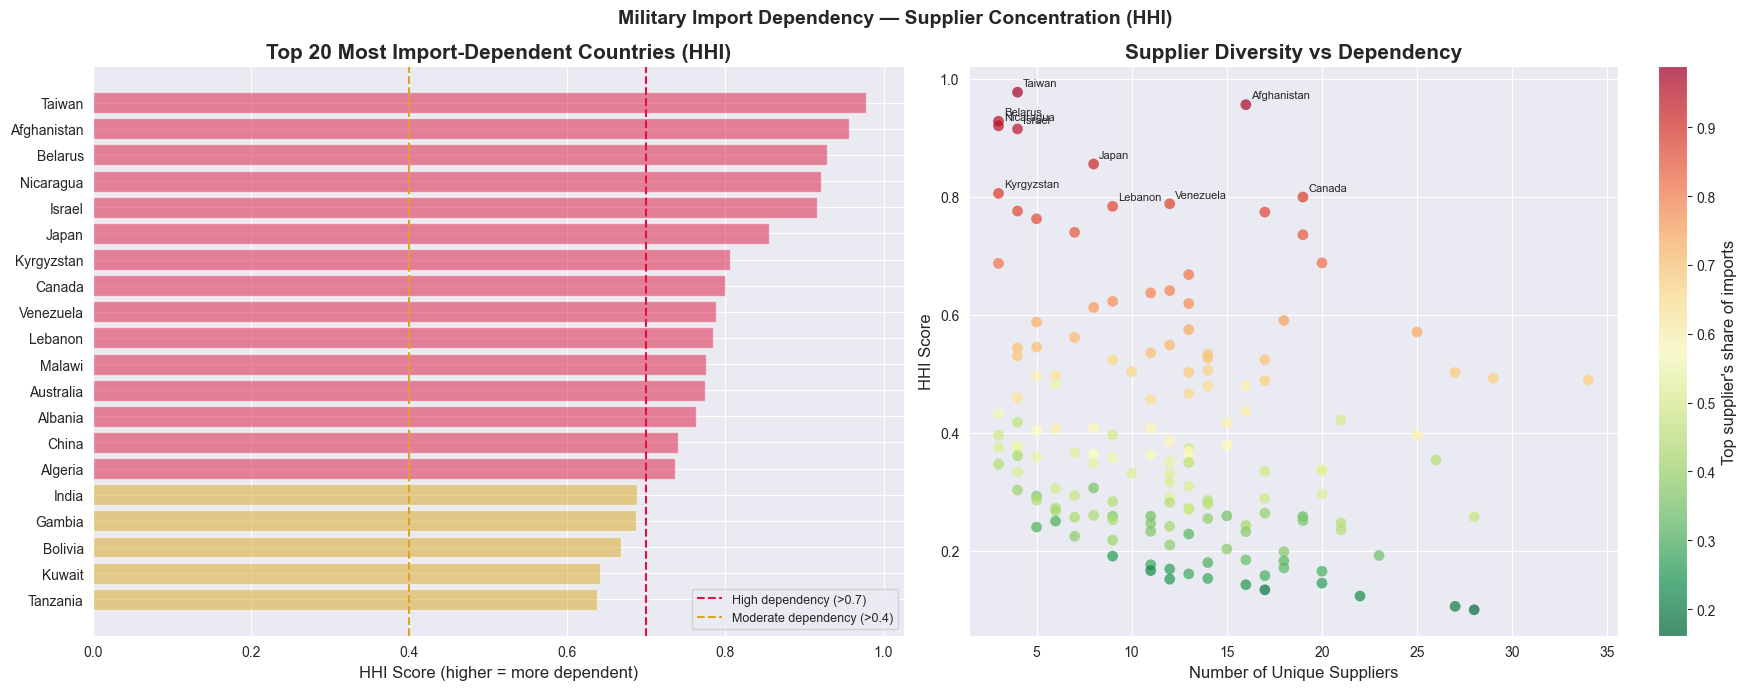

In [34]:
# Herfindahl-Hirschman Index (HHI) — measures import source concentration per country
# HHI = 1.0 → 100% dependent on a single supplier (maximum vulnerability)
# HHI → 0  → perfectly diversified across many suppliers

import_weights = df.groupby(['target', 'source'])['quantity'].sum().reset_index()
import_weights.columns = ['importer', 'exporter', 'qty']

hhi_rows = []
for country, grp in import_weights.groupby('importer'):
    total = grp['qty'].sum()
    shares = grp['qty'] / total
    hhi = (shares ** 2).sum()
    top_supplier = grp.loc[grp['qty'].idxmax(), 'exporter']
    top_share = grp['qty'].max() / total
    hhi_rows.append({
        'country': country,
        'hhi': hhi,
        'top_supplier': top_supplier,
        'top_supplier_share': top_share,
        'n_suppliers': len(grp),
    })

hhi_df = pd.DataFrame(hhi_rows).sort_values('hhi', ascending=False)

top_dep = hhi_df[hhi_df['n_suppliers'] >= 3].head(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Military Import Dependency — Supplier Concentration (HHI)', 
             fontsize=14, fontweight='bold')

colors_hhi = ['crimson' if h > 0.7 else 'goldenrod' if h > 0.4 else 'steelblue'
              for h in top_dep['hhi']]
axes[0].barh(top_dep['country'][::-1], top_dep['hhi'][::-1], color=colors_hhi[::-1], alpha=0.5)
axes[0].axvline(0.7, color='crimson', ls='--', lw=1.5, label='High dependency (>0.7)')
axes[0].axvline(0.4, color='goldenrod', ls='--', lw=1.5, label='Moderate dependency (>0.4)')
axes[0].set(title='Top 20 Most Import-Dependent Countries (HHI)',
            xlabel='HHI Score (higher = more dependent)')
axes[0].legend(fontsize=9)

scatter_data = hhi_df[hhi_df['n_suppliers'] >= 3]
sc = axes[1].scatter(scatter_data['n_suppliers'], scatter_data['hhi'],
                     c=scatter_data['top_supplier_share'], cmap='RdYlGn_r',
                     s=60, alpha=0.7, edgecolor='none')
plt.colorbar(sc, ax=axes[1], label="Top supplier's share of imports")

high_dep = scatter_data[scatter_data['hhi'] > 0.6].head(10)
for _, row in high_dep.iterrows():
    axes[1].annotate(row['country'], (row['n_suppliers'], row['hhi']),
                     fontsize=8, ha='left', va='bottom',
                     xytext=(4, 3), textcoords='offset points')

axes[1].set(title='Supplier Diversity vs Dependency',
            xlabel='Number of Unique Suppliers', ylabel='HHI Score')
plt.tight_layout()
plt.show()

In [35]:
# Summary table
print("\nTop 15 Most Militarily Dependent Countries:")
print(hhi_df[hhi_df['n_suppliers'] >= 3].head(15)[
    ['country', 'hhi', 'top_supplier', 'top_supplier_share', 'n_suppliers']
].round(3).to_string(index=False))


Top 15 Most Militarily Dependent Countries:
    country   hhi  top_supplier  top_supplier_share  n_suppliers
     Taiwan 0.977 United States               0.989            4
Afghanistan 0.956 United States               0.978           16
    Belarus 0.928        Russia               0.963            3
  Nicaragua 0.920        Russia               0.959            3
     Israel 0.915 United States               0.956            4
      Japan 0.856 United States               0.924            8
 Kyrgyzstan 0.806        Russia               0.893            3
     Canada 0.800 United States               0.892           19
  Venezuela 0.788        Russia               0.884           12
    Lebanon 0.784 United States               0.881            9
     Malawi 0.776  South Africa               0.877            4
  Australia 0.774 United States               0.878           17
    Albania 0.763 United States               0.869            5
      China 0.740        Russia              

### 🔑 Key Takeaways

- **Blocs are controlled by patron states:**  
Each community is anchored by a main supplier → member countries depend on patron for military capability.

- **Bridge countries are key risk points:**  
Countries connecting multiple blocs (especially true brokers) can distrupt the entire system if their alignment shifts.

- **High HHI = high dependency:**  
Countries with very concentrated suppliers cannot rearm independently →  they lack strategic autonomy in conflict.

- **The system is hierarchical:**  
A small core of powerful states, a layer of brokers, and a large dependent periphery → power is centralized, not balanced.

---

## Summary

### What the Network Looks Like

The Global arms transfer network (2000-2023) is sparse but unequal — low in density, dominated by a handful of major exporters, and organized around a clear core-periphery structure. A few countries sit at the center, supplying many; most countries sit at the periphery, buying from few.

The network is **small world topologically** (APL ≈ 2.38, diameter ≈ 6) but **economically distant** (weighted APL ≈ 17) — countries are structurally reachable within a few hops, but strong trade pathways are rare and heavily concentrated.

---

### What We Found

**Arms trade is highly concentrated (heavy-tailed):**  
A few countries dominate global supply. The distribution fits **lognormal better than power-law**, meaning concentration is extreme but still constrained by real-world limits.

**Connection exist, but strong trade is asymmetrical:**  
Countries often form trade triangles topologically, but high-volume flows are **one-sided and directional**, not mutually balanced.

**The United States is the main structural hub:**  
It dominates **degree, betweenness, and eigenvector**, acting as the central broker — but not PageRank, since it exports more than it recieves.

**Ukraine is the main flow destination:**  
High PageRank reflects **massive inflows from top suppliers (post-2022)** → importance comes from being heavily supplied by powerful countries.

**Indirect influence matters:**  
Countries like **Malaysia and Pakistan** rank high due to **strong indirect connections**, not direct volume.

**Weight normalization changes structure:**  
Raw data shows **5 blocs (clear hierarchy)**, while normalized data collapses into **3 blocs (more homogeneous)** → normalization suppresses the differences between large and small transfers, making the network appear more homogeneous and erasing bloc boundries that are only meaningful because of volume asymmetries. The 5-bloc structure is the more geopolitically informative result.

---

### Conclusion
The global arms trade is not a level playing field. It is a hierarchical dependency system where a small number of patron states hold structural leverage over entire blocs of militarily dependent nations. Brokers mediate between these blocs, and a large periphery of high-HHI importers has effectively surrendered strategic autonomy to their top supplier.

Netowkr analysis makes visible what political declarations often obscure: military dependency is encoded in trade structure, and the real balance of power is far more concentrated than official alliances suggest. In an increasingly unstable world, the countries most capable of triggering or preventing large-scale conflict are not necessarily the ones with the largest armies — they  are the ones that control the flow of arms to everyone else.

---